# Deep Learning – Lab 7: End-to-End Deep Learning Challenge
## Predicting Bank Marketing Campaign Success

**Institution:** ENSIA – Higher National School of Artificial Intelligence  
**Course:** Deep Learning (Y4 / S7)  
**Lab Assignment:** Lab 7 – End-to-End Deep Learning Challenge  
**Dataset:** Bank Marketing (UCI Machine Learning Repository) – `bank-full.csv`

---

### Objectives
1. Explore and preprocess a real-world dataset containing heterogeneous features.
2. Establish a majority-class classifier and a Logistic Regression baseline.
3. Design, train, and optimize a Feed-Forward Neural Network using TensorFlow/Keras.
4. Address challenges associated with class imbalance and evaluate mitigation strategies.
5. Perform final evaluation on a held-out test set and formulate practical business decision recommendations.


---
## Setup & Environment

### 1. Import Required Packages
We import all packages required for data manipulation, visualization, preprocessing, baseline modeling, evaluation, and neural network construction.

In [1]:
# General and Data Handling
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')

# Scikit-learn: Preprocessing, Pipelines & Selection
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight

# Scikit-learn: Baselines & Metrics
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

# Silence CUDA driver initialization warnings for AMD/CPU environment
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

# TensorFlow & Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks, optimizers

# Reproducibility seeds
np.random.seed(42)
tf.random.set_seed(42)

# Plotting configuration
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print(f"TensorFlow Version: {tf.__version__}")
print("All required packages imported successfully!")

# Display configuration
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)


I0000 00:00:1795638799.448806  235150 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow Version: 2.21.0
All required packages imported successfully!


I0000 00:00:1795638800.340706  235150 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


### 2. Load the Dataset
The dataset `bank-full.csv` contains 45,211 records and 17 columns (16 input features + 1 target variable `y`). The separator is semicolon (`;`).


In [2]:
# Load the dataset
data_path = 'bank-full.csv'
df = pd.read_csv(data_path, sep=';')

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()


Dataset Shape: 45211 rows, 17 columns


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


---
## Part I – Data Exploration

### 1.1 Dataset Structure & Summary Statistics
We inspect column data types, duplicate counts, explicit and disguised (`unknown`) missing values, and descriptive statistics for numerical and categorical features.

=== Dataset Information ===
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB

Duplicate rows: 0

Explicit NaN counts:
age          0
job          0
marital      0
education    0
defa

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000



=== Categorical Features Summary ===


,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211
unique,12,3,4,2,2,2,3,12,4,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,unknown,no
freq,9732,27214,23202,44396,25130,37967,29285,13766,36959,39922
top_freq_%,21.53%,60.19%,51.32%,98.20%,55.58%,83.98%,64.77%,30.45%,81.75%,88.30%



=== Unique Values per Categorical Feature ===


,Unique Count,Top Category (Share),All Unique Categories
job,12,blue-collar (21.5%),"management, technician, entrepreneur, blue-collar, unknown, retired, admin., services, self-employed, unemployed, housemaid, student"
marital,3,married (60.2%),"married, single, divorced"
education,4,secondary (51.3%),"tertiary, secondary, unknown, primary"
default,2,no (98.2%),"no, yes"
housing,2,yes (55.6%),"yes, no"
loan,2,no (84.0%),"no, yes"
contact,3,cellular (64.8%),"unknown, cellular, telephone"
month,12,may (30.4%),"may, jun, jul, aug, oct, nov, dec, jan, feb, mar, apr, sep"
poutcome,4,unknown (81.7%),"unknown, failure, other, success"
y,2,no (88.3%),"no, yes"



=== Distributions of Features with >= 3 Categories ===


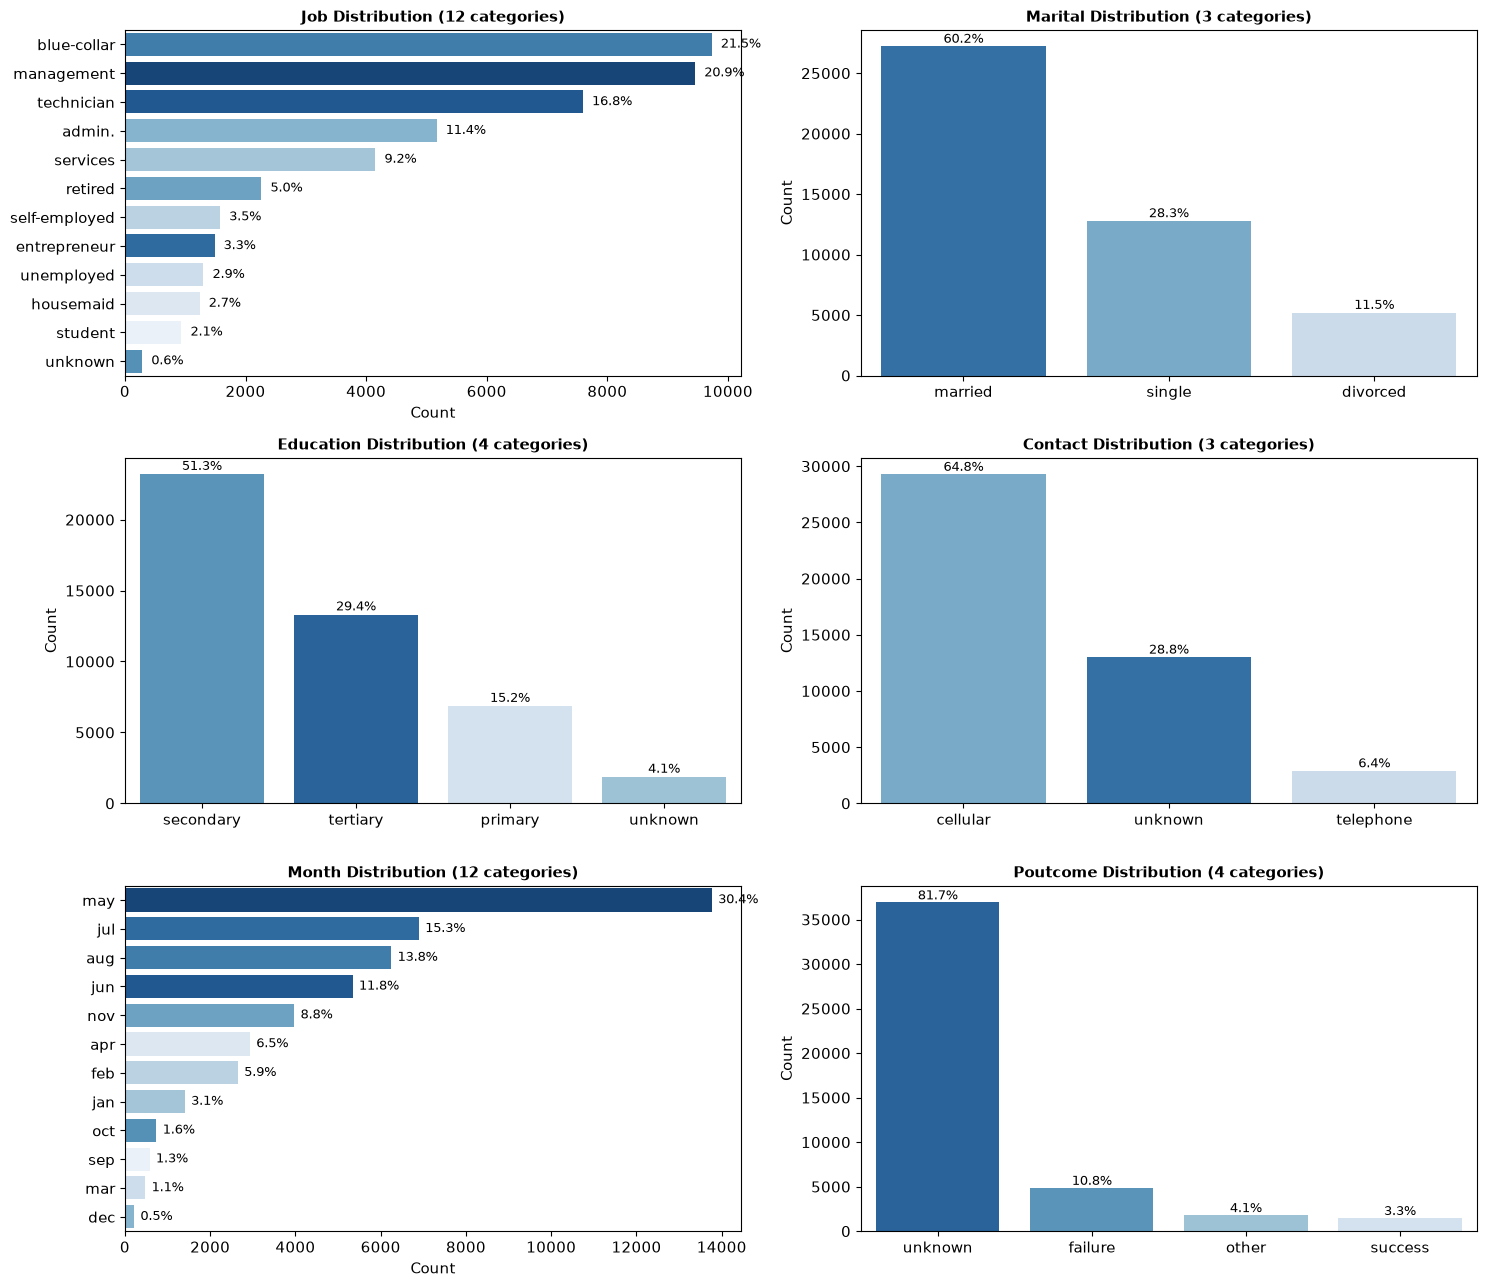

In [3]:
# Basic dataset dimensions and info
print("=== Dataset Information ===")
df.info()

# Check for duplicate rows
print(f"\nDuplicate rows: {df.duplicated().sum()}")

# Check for explicit missing values (NaN)
print(f"\nExplicit NaN counts:\n{df.isnull().sum()}")

# Check for disguised missing values ('unknown' placeholder)
print("\n'unknown' counts per column:")
unknown_counts = (df == "unknown").sum()
print(unknown_counts[unknown_counts > 0])

# Summary statistics for numerical features
print("\n=== Numerical Features Summary ===")
display(df.describe())

# Summary statistics for categorical features (with frequency percentage of top class)
print("\n=== Categorical Features Summary ===")
cat_summary = df.describe(include=["object", "string"]).copy()
cat_summary.loc["top_freq_%"] = (cat_summary.loc["freq"] / cat_summary.loc["count"] * 100).map("{:.2f}%".format)
display(cat_summary)

# Detailed breakdown listing all unique values per categorical feature (full width, no truncation)
print("\n=== Unique Values per Categorical Feature ===")
cat_cols = df.select_dtypes(include=["object", "string"]).columns
unique_summary = pd.DataFrame({
    "Unique Count": [df[col].nunique() for col in cat_cols],
    "Top Category (Share)": [f"{df[col].mode()[0]} ({df[col].value_counts(normalize=True).iloc[0]:.1%})" for col in cat_cols],
    "All Unique Categories": [", ".join(map(str, df[col].unique())) for col in cat_cols]
}, index=cat_cols)

with pd.option_context("display.max_colwidth", None, "display.width", 1000):
    display(unique_summary)

# Distributions of multi-category features (>= 3 unique values)
print("\n=== Distributions of Features with >= 3 Categories ===")
multi_cat_cols = [col for col in cat_cols if df[col].nunique() >= 3]

fig, axes = plt.subplots(3, 2, figsize=(15, 13))
axes = axes.flatten()

for idx, col in enumerate(multi_cat_cols):
    ax = axes[idx]
    order = df[col].value_counts().index
    total = len(df)
    
    if col in ["job", "month"]:
        # Horizontal bar plot for features with 12 categories
        sns.countplot(data=df, y=col, order=order, ax=ax, palette="Blues_r", hue=col, legend=False)
        ax.set_title(f"{col.capitalize()} Distribution ({df[col].nunique()} categories)", fontsize=11, fontweight="bold")
        ax.set_xlabel("Count")
        ax.set_ylabel("")
        for p in ax.patches:
            w = p.get_width()
            ax.annotate(f"{w/total:.1%}", (w + 150, p.get_y() + p.get_height() / 2), va="center", fontsize=9)
    else:
        # Vertical bar plot for features with 3-4 categories
        sns.countplot(data=df, x=col, order=order, ax=ax, palette="Blues_r", hue=col, legend=False)
        ax.set_title(f"{col.capitalize()} Distribution ({df[col].nunique()} categories)", fontsize=11, fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylabel("Count")
        for p in ax.patches:
            h = p.get_height()
            ax.annotate(f"{h/total:.1%}", (p.get_x() + p.get_width() / 2, h + 300), ha="center", fontsize=9)

plt.tight_layout()
plt.show()


### 1.2 Exploratory Data Analysis & Visualizations
We explore feature distributions, conversion rates across categories, correlations, and non-linear relationships with the target variable `y`.

=== 1. Categorical Feature Discriminative Power Ranking ===


,Feature,Categories,Min Rate,Max Rate,Spread (%),Best Category,Worst Category
0,poutcome,4,9.2%,64.7%,55.6%,success (64.7%),unknown (9.2%)
1,month,12,6.7%,52.0%,45.3%,mar (52.0%),may (6.7%)
2,job,12,7.3%,28.7%,21.4%,student (28.7%),blue-collar (7.3%)
3,contact,3,4.1%,14.9%,10.8%,cellular (14.9%),unknown (4.1%)
4,housing,2,7.7%,16.7%,9.0%,no (16.7%),yes (7.7%)
5,education,4,8.6%,15.0%,6.4%,tertiary (15.0%),primary (8.6%)
6,loan,2,6.7%,12.7%,6.0%,no (12.7%),yes (6.7%)
7,default,2,6.4%,11.8%,5.4%,no (11.8%),yes (6.4%)
8,marital,3,10.1%,14.9%,4.8%,single (14.9%),married (10.1%)



=== 2. Numerical Feature Comparison & Skewness Profile ===


,Feature,Median (No),Median (Yes),Mean (No),Mean (Yes),Correlation (r),Skewness
0,duration,164.0,426.0,221.2,537.3,+0.395,3.14
1,pdays,-1.0,-1.0,36.4,68.7,+0.104,2.62
2,previous,0.0,0.0,0.5,1.2,+0.093,41.85
3,campaign,2.0,2.0,2.8,2.1,-0.073,4.90
4,balance,417.0,733.0,1303.7,1804.3,+0.053,8.36
5,day,16.0,15.0,15.9,15.2,-0.028,0.09
6,age,39.0,38.0,40.8,41.7,+0.025,0.68


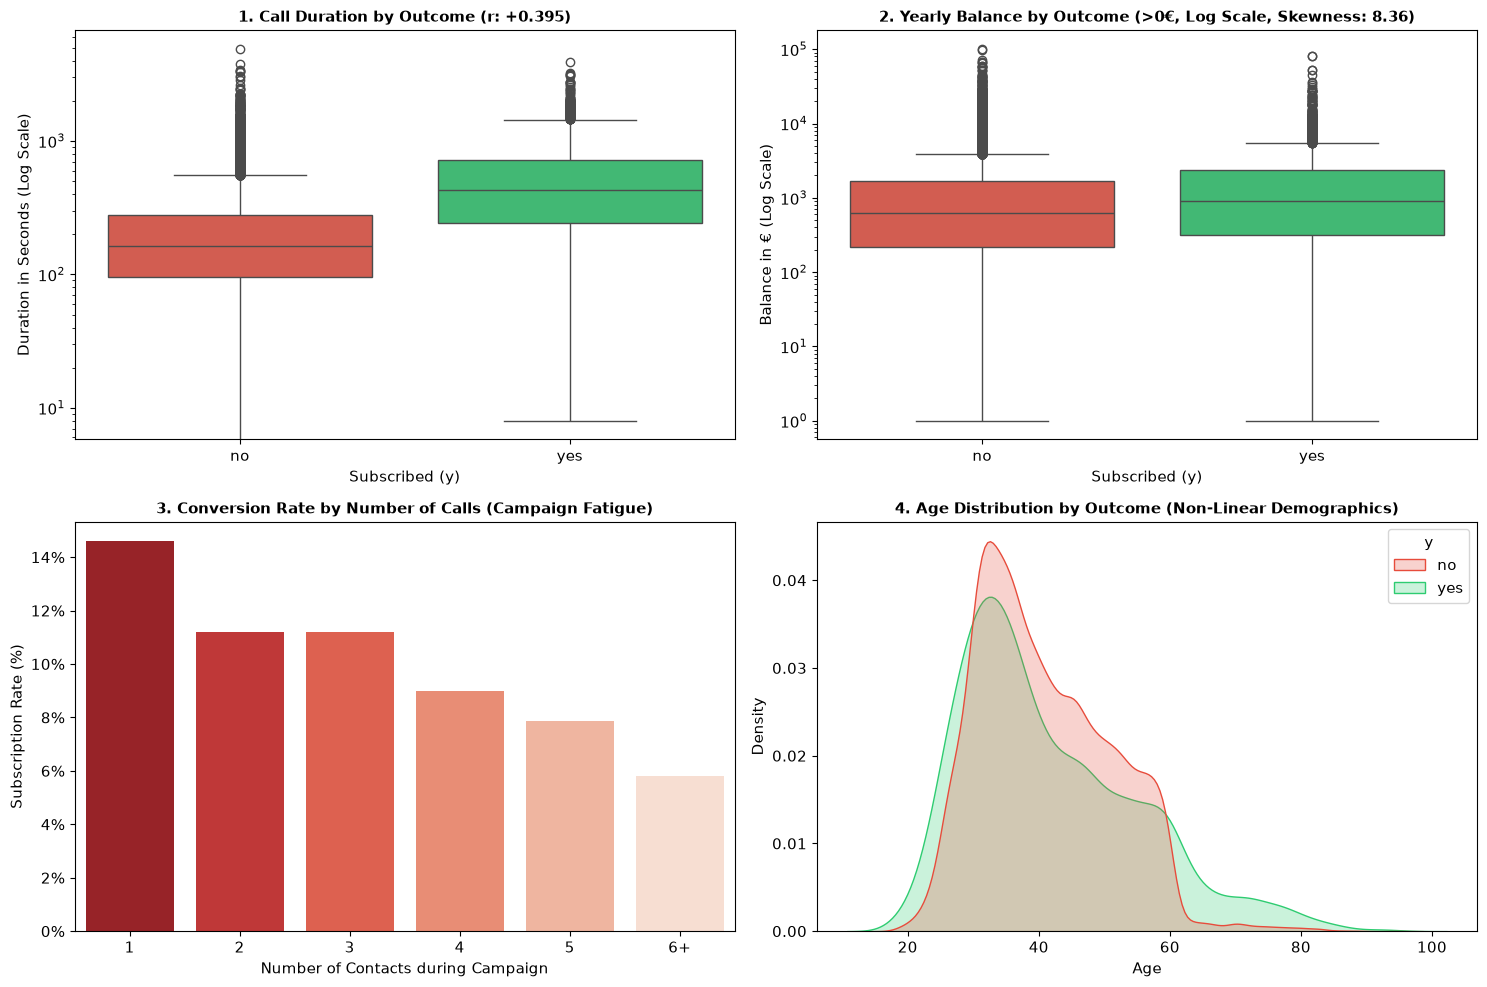

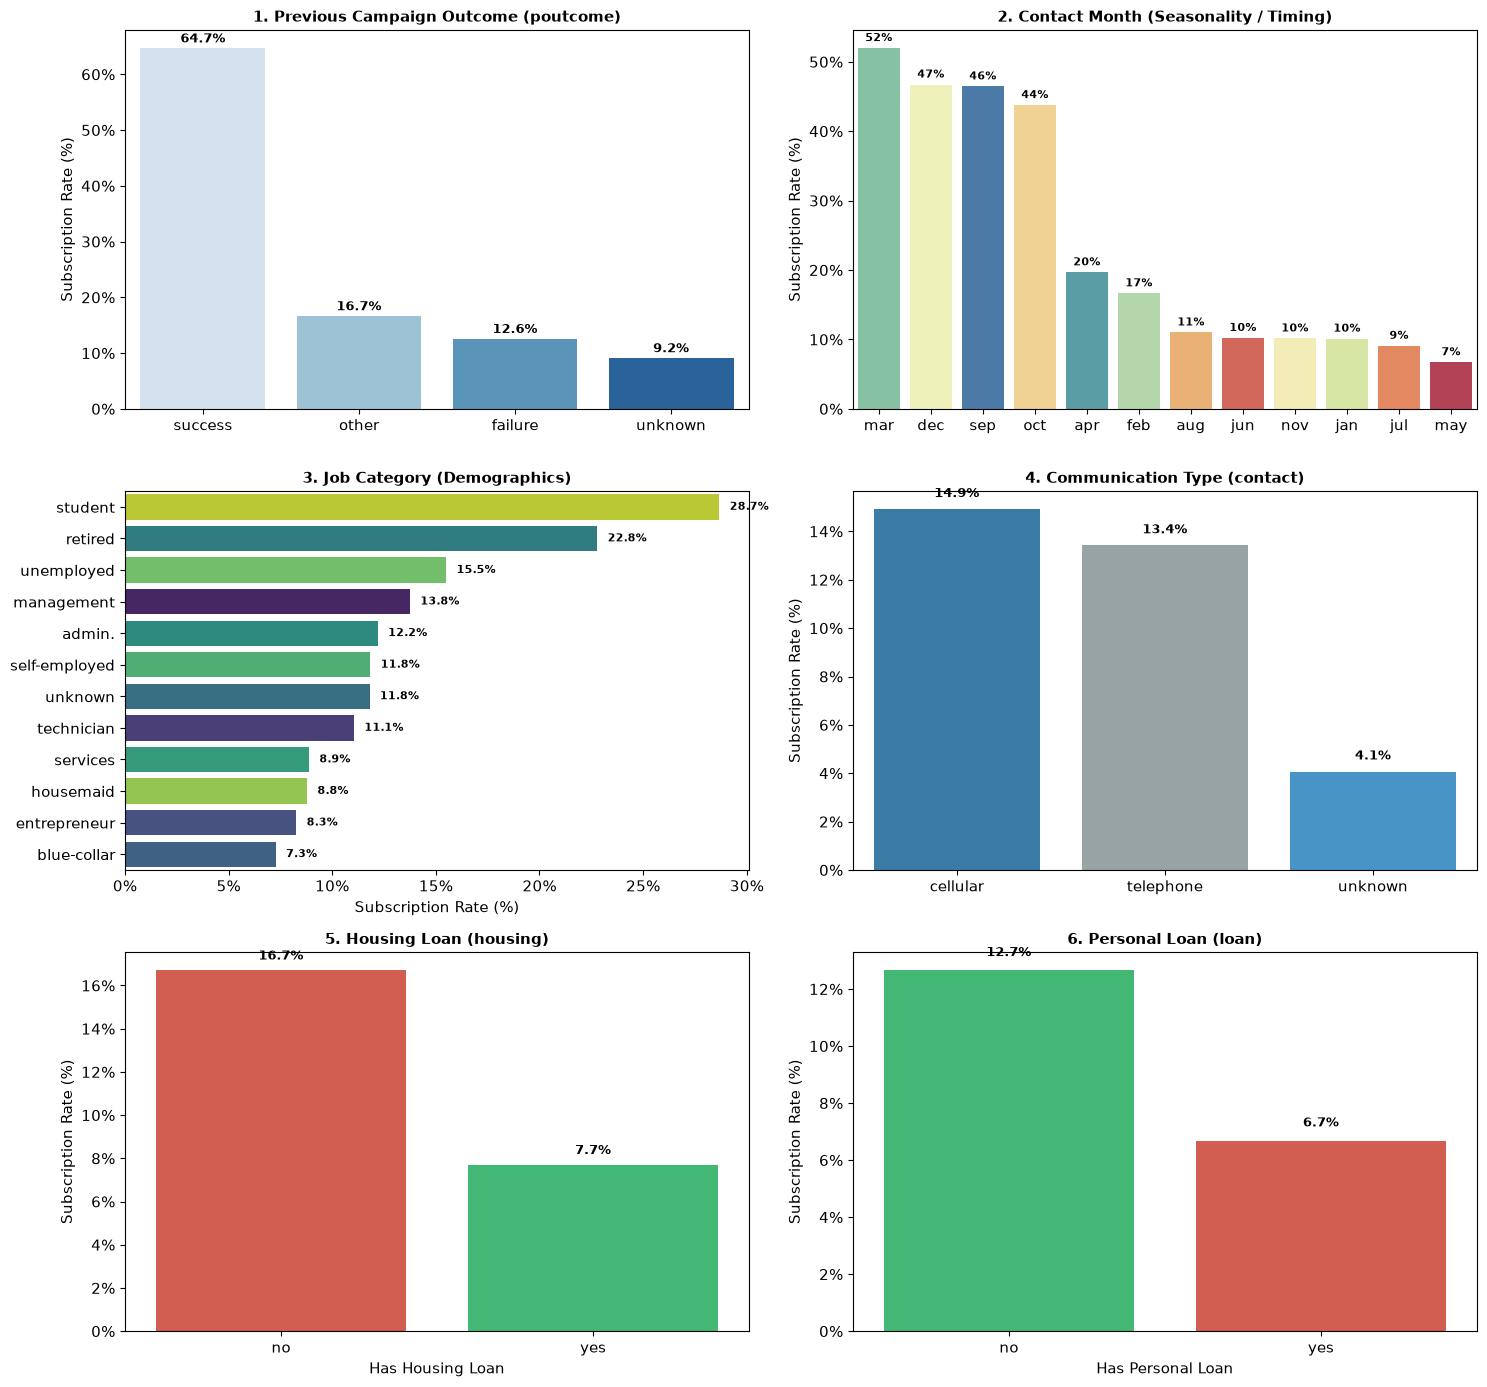

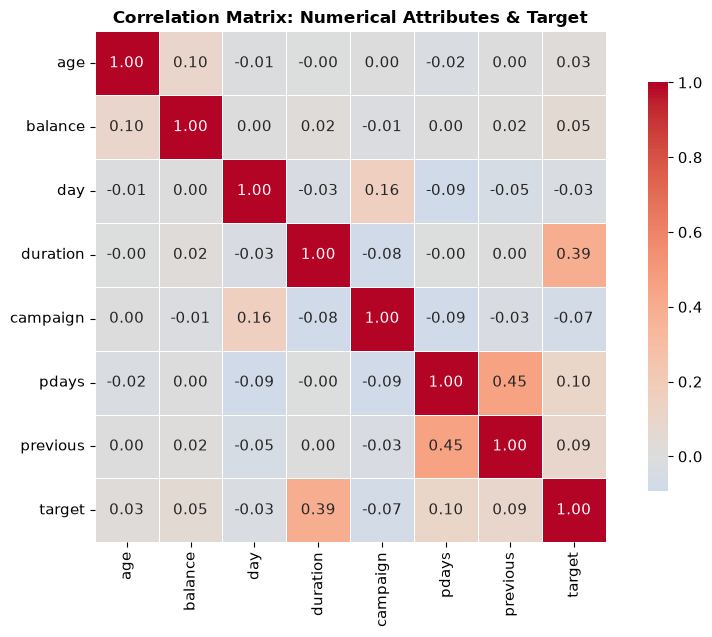

In [4]:
# Temporary binary target for EDA correlations and conversion rates
df["target"] = (df["y"] == "yes").astype(int)

# ===================================================================
# Step 1: Quantitative Screening of Features
# ===================================================================

# A. Categorical Feature Screening (Conversion Rate Spread: Max - Min)
print("=== 1. Categorical Feature Discriminative Power Ranking ===")
cat_cols = [c for c in df.select_dtypes(include=["object", "string"]).columns if c != "y"]
cat_records = []
for col in cat_cols:
    rates = df.groupby(col)["target"].mean()
    spread = rates.max() - rates.min()
    cat_records.append({
        "Feature": col,
        "Categories": df[col].nunique(),
        "Min Rate": f"{rates.min():.1%}",
        "Max Rate": f"{rates.max():.1%}",
        "Spread (Max - Min)": spread,
        "Spread (%)": f"{spread:.1%}",
        "Best Category": f"{rates.idxmax()} ({rates.max():.1%})",
        "Worst Category": f"{rates.idxmin()} ({rates.min():.1%})"
    })
cat_ranking_df = pd.DataFrame(cat_records).sort_values(by="Spread (Max - Min)", ascending=False)
cat_ranking_df.drop(columns=["Spread (Max - Min)"], inplace=True)
cat_ranking_df.reset_index(drop=True, inplace=True)
display(cat_ranking_df)

# B. Numerical Feature Screening (Correlation, Class Medians, Means & Skewness)
print("\n=== 2. Numerical Feature Comparison & Skewness Profile ===")
num_cols = ["duration", "balance", "age", "day", "campaign", "pdays", "previous"]
num_records = []
for col in num_cols:
    med_no = df[df["target"] == 0][col].median()
    med_yes = df[df["target"] == 1][col].median()
    mean_no = df[df["target"] == 0][col].mean()
    mean_yes = df[df["target"] == 1][col].mean()
    corr = df[col].corr(df["target"])
    skew = df[col].skew()
    num_records.append({
        "Feature": col,
        "Median (No)": med_no,
        "Median (Yes)": med_yes,
        "Mean (No)": f"{mean_no:.1f}",
        "Mean (Yes)": f"{mean_yes:.1f}",
        "Correlation (r)": f"{corr:+.3f}",
        "abs_corr": abs(corr),
        "Skewness": f"{skew:.2f}"
    })
num_ranking_df = pd.DataFrame(num_records).sort_values(by="abs_corr", ascending=False)
num_ranking_df.drop(columns=["abs_corr"], inplace=True)
num_ranking_df.reset_index(drop=True, inplace=True)
display(num_ranking_df)

# ===================================================================
# Step 2: Visualizations of Key Numerical Features vs Target
# ===================================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Duration (Log-scale boxplot)
sns.boxplot(data=df, x="y", y="duration", hue="y", ax=axes[0, 0],
            palette=["#e74c3c", "#2ecc71"], legend=False)
axes[0, 0].set_yscale("log")
axes[0, 0].set_title("1. Call Duration by Outcome (r: +0.395)", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("Subscribed (y)")
axes[0, 0].set_ylabel("Duration in Seconds (Log Scale)")

# 2. Balance (Log-scale boxplot for positive balances)
df_pos_bal = df[df["balance"] > 0].copy()
sns.boxplot(data=df_pos_bal, x="y", y="balance", hue="y", ax=axes[0, 1],
            palette=["#e74c3c", "#2ecc71"], legend=False)
axes[0, 1].set_yscale("log")
axes[0, 1].set_title("2. Yearly Balance by Outcome (>0€, Log Scale, Skewness: 8.36)", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("Subscribed (y)")
axes[0, 1].set_ylabel("Balance in € (Log Scale)")

# 3. Campaign (Call Fatigue / Diminishing Returns)
df["campaign_binned"] = df["campaign"].clip(upper=6)
camp_rates = df.groupby("campaign_binned")["target"].mean()
camp_labels = [f"{i}" if i < 6 else "6+" for i in camp_rates.index]
sns.barplot(x=camp_labels, y=camp_rates.values, ax=axes[1, 0], palette="Reds_r", hue=camp_labels, legend=False)
axes[1, 0].set_title("3. Conversion Rate by Number of Calls (Campaign Fatigue)", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("Number of Contacts during Campaign")
axes[1, 0].set_ylabel("Subscription Rate (%)")
axes[1, 0].yaxis.set_major_formatter("{x:.0%}")
df.drop(columns=["campaign_binned"], inplace=True)

# 4. Age Distribution (KDE - Non-linear Demographics)
sns.kdeplot(data=df, x="age", hue="y", common_norm=False, fill=True, ax=axes[1, 1],
            palette=["#e74c3c", "#2ecc71"])
axes[1, 1].set_title("4. Age Distribution by Outcome (Non-Linear Demographics)", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("Age")
axes[1, 1].set_ylabel("Density")

plt.tight_layout()
plt.show()

# ===================================================================
# Step 3: Visualizations of Categorical Features (Separated per Feature)
# ===================================================================
fig, axes = plt.subplots(3, 2, figsize=(15, 14))

# 1. Poutcome
p_order = df.groupby("poutcome")["target"].mean().sort_values(ascending=False).index
sns.barplot(data=df, x="poutcome", y="target", order=p_order, hue="poutcome", ax=axes[0, 0],
            palette="Blues_r", errorbar=None, legend=False)
axes[0, 0].set_title("1. Previous Campaign Outcome (poutcome)", fontsize=11, fontweight="bold")
axes[0, 0].set_ylabel("Subscription Rate (%)")
axes[0, 0].set_xlabel("")
axes[0, 0].yaxis.set_major_formatter("{x:.0%}")
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f"{p.get_height():.1%}", (p.get_x() + p.get_width() / 2, p.get_height() + 0.01),
                        ha="center", fontsize=9, fontweight="bold")

# 2. Month
m_order = df.groupby("month")["target"].mean().sort_values(ascending=False).index
sns.barplot(data=df, x="month", y="target", order=m_order, hue="month", ax=axes[0, 1],
            palette="Spectral", errorbar=None, legend=False)
axes[0, 1].set_title("2. Contact Month (Seasonality / Timing)", fontsize=11, fontweight="bold")
axes[0, 1].set_ylabel("Subscription Rate (%)")
axes[0, 1].set_xlabel("")
axes[0, 1].yaxis.set_major_formatter("{x:.0%}")
for p in axes[0, 1].patches:
    axes[0, 1].annotate(f"{p.get_height():.0%}", (p.get_x() + p.get_width() / 2, p.get_height() + 0.01),
                        ha="center", fontsize=8, fontweight="bold")

# 3. Job
j_order = df.groupby("job")["target"].mean().sort_values(ascending=False).index
sns.barplot(data=df, x="target", y="job", order=j_order, hue="job", ax=axes[1, 0],
            palette="viridis", errorbar=None, legend=False)
axes[1, 0].set_title("3. Job Category (Demographics)", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("Subscription Rate (%)")
axes[1, 0].set_ylabel("")
axes[1, 0].xaxis.set_major_formatter("{x:.0%}")
for p in axes[1, 0].patches:
    w = p.get_width()
    axes[1, 0].annotate(f"{w:.1%}", (w + 0.005, p.get_y() + p.get_height() / 2),
                        va="center", fontsize=8, fontweight="bold")

# 4. Contact Channel
c_order = df.groupby("contact")["target"].mean().sort_values(ascending=False).index
sns.barplot(data=df, x="contact", y="target", order=c_order, hue="contact", ax=axes[1, 1],
            palette=["#3498db", "#2980b9", "#95a5a6"], errorbar=None, legend=False)
axes[1, 1].set_title("4. Communication Type (contact)", fontsize=11, fontweight="bold")
axes[1, 1].set_ylabel("Subscription Rate (%)")
axes[1, 1].set_xlabel("")
axes[1, 1].yaxis.set_major_formatter("{x:.0%}")
for p in axes[1, 1].patches:
    axes[1, 1].annotate(f"{p.get_height():.1%}", (p.get_x() + p.get_width() / 2, p.get_height() + 0.005),
                        ha="center", fontsize=9, fontweight="bold")

# 5. Housing Loan
h_order = ["no", "yes"]
sns.barplot(data=df, x="housing", y="target", order=h_order, hue="housing", ax=axes[2, 0],
            palette=["#2ecc71", "#e74c3c"], errorbar=None, legend=False)
axes[2, 0].set_title("5. Housing Loan (housing)", fontsize=11, fontweight="bold")
axes[2, 0].set_ylabel("Subscription Rate (%)")
axes[2, 0].set_xlabel("Has Housing Loan")
axes[2, 0].yaxis.set_major_formatter("{x:.0%}")
for p in axes[2, 0].patches:
    axes[2, 0].annotate(f"{p.get_height():.1%}", (p.get_x() + p.get_width() / 2, p.get_height() + 0.005),
                        ha="center", fontsize=9, fontweight="bold")

# 6. Personal Loan
l_order = ["no", "yes"]
sns.barplot(data=df, x="loan", y="target", order=l_order, hue="loan", ax=axes[2, 1],
            palette=["#2ecc71", "#e74c3c"], errorbar=None, legend=False)
axes[2, 1].set_title("6. Personal Loan (loan)", fontsize=11, fontweight="bold")
axes[2, 1].set_ylabel("Subscription Rate (%)")
axes[2, 1].set_xlabel("Has Personal Loan")
axes[2, 1].yaxis.set_major_formatter("{x:.0%}")
for p in axes[2, 1].patches:
    axes[2, 1].annotate(f"{p.get_height():.1%}", (p.get_x() + p.get_width() / 2, p.get_height() + 0.005),
                        ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

# ===================================================================
# Step 4: Correlation Heatmap (Numerical Features + Target)
# ===================================================================
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(9, 6.5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation Matrix: Numerical Attributes & Target", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# Clean up temporary target column
df.drop(columns=["target"], inplace=True)


### 1.3 Target Variable Distribution & Imbalance
We inspect the class distribution of `y` (`yes` vs. `no`) in raw counts and percentages to quantify the class imbalance ratio.

,Count,Percentage
y,,
no,39922,88.30%
yes,5289,11.70%


Imbalance Ratio: 7.55:1 (roughly 1 subscriber for every 8 non-subscribers)


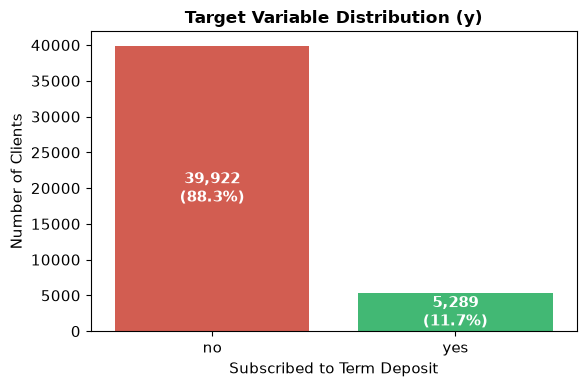

In [5]:
# Target variable counts, percentage, and exact imbalance ratio
target_counts = df["y"].value_counts()
target_pct = df["y"].value_counts(normalize=True)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_pct.map("{:.2%}".format)
})
display(target_summary)

imbalance_ratio = target_counts["no"] / target_counts["yes"]
print(f"Imbalance Ratio: {imbalance_ratio:.2f}:1 (roughly 1 subscriber for every {round(imbalance_ratio)} non-subscribers)")

# Concise count plot with percentage annotations
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="y", hue="y", palette=["#e74c3c", "#2ecc71"], legend=False)
for p in ax.patches:
    h = p.get_height()
    pct = h / len(df) * 100
    ax.annotate(f"{int(h):,}\n({pct:.1f}%)", (p.get_x() + p.get_width() / 2, h / 2),
                ha="center", va="center", color="white", fontweight="bold", fontsize=11)
plt.title("Target Variable Distribution (y)", fontsize=12, fontweight="bold")
plt.xlabel("Subscribed to Term Deposit")
plt.ylabel("Number of Clients")
plt.tight_layout()
plt.show()


### 1.4 Discussion of Findings

#### 1. Dataset Quality & Overall Characteristics
* **Data Cleanliness & Missing Values:** The dataset contains 45,211 records with zero duplicate rows and zero explicit missing values (`NaN`). However, several categorical columns use `unknown` as a placeholder: notably `poutcome` (81.8%), `contact` (28.8%), and `education` (4.1%). Rather than random corruption, these primarily represent unrecorded or structurally non-applicable business states (e.g., `unknown` in `poutcome` corresponds almost entirely to clients who were never contacted in prior campaigns).

#### 2. Client Profile & Feature Distributions
* **Demographics (Age, Marital Status & Education):**
  * **Marital Status:** A clear majority of the bank's clients are **married (60.2%)**, while 28.3% are single and 11.5% are divorced.
  * **Age Distribution:** The client base has an average age of **40.9 years** (median: 39 years, spanning 18 to 95). Half of all clients are concentrated between 33 and 48 years old, representing a prime working-age demographic.
  * **Education Level:** Over half of the clients have completed **secondary education (51.3%)**, followed by tertiary education (29.4%) and primary education (15.2%).
* **Occupational Profile (`job`):**
  * The job distribution reflects a realistic retail banking customer base: heavily anchored by **blue-collar workers (21.5%)**, **management professionals (20.9%)**, and **technicians (16.8%)**, which together constitute nearly 60% of all clients. Smaller segments include administrative staff (11.4%), services (9.2%), retired individuals (5.0%), and students (2.1%).
* **Operational & Historical Interaction (`contact`, `poutcome`, `month`):**
  * **Communication Channel:** Most contacts with recorded channels were conducted via **cellular phones (64.8%)**, with traditional telephone landlines accounting for only 6.4%, while 28.8% are recorded as unknown.
  * **Historical Interaction (`poutcome`):** For **81.8% of clients**, the previous campaign outcome is `unknown` because this marketing effort was their first recorded interaction (`pdays = -1`). Only 10.8% had a prior campaign failure and 3.4% a prior success.
  * **Campaign Seasonality:** Contact volume is heavily concentrated in **May (30.5%)**, followed by July (15.3%) and August (13.8%), showing strong seasonal marketing pushes.
* **Financial Profile (`housing`, `loan`, `balance`, `default`):**
  * **Debt & Liabilities:** More than half of all clients hold a **housing loan / mortgage (55.6%)**, and 16.0% have a **personal loan**. Conversely, credit default is rare (only 1.8% of clients are in default).
  * **Account Balance:** While the median balance is modest at **448 €** (mean: 1,362 €), the distribution is heavily skewed with negative balances down to -8,019 € and extreme outliers exceeding 100,000 €.

#### 3. Key Relationships Between Features and Target Variable (`y`)
* **Numerical Predictors:**
  * **Call Duration (`duration`):** By far the strongest linear predictor ($r = +0.395$). Median duration for subscribers is **426 seconds** (~7.1 mins) versus **164 seconds** (~2.7 mins) for non-subscribers (2.6× longer). *Crucial Modeling Note:* While highly predictive, `duration` introduces severe **target leakage** in real-world deployment since it is unknown prior to dialing.
  * **Account Balance (`balance`):** Although subscribers show a noticeably higher median balance (733 € vs 417 €, a 75% increase), this difference is not a dominant standalone discriminator due to high internal variance and heavy distribution overlap. However, we can still notice that higher financial liquidity provides a positive secondary signal when combined with other client attributes.
  * **Campaign Contacts (`campaign`):** Exhibits negative correlation ($r = -0.073$). Conversion is highest on the 1st contact (**14.6%**), drops to **11.2%** on the 2nd–3rd contacts, and declines to **5.8%** at 6+ calls (**7.35%** overall for 4+ calls), indicating **call fatigue and diminishing returns**.
  * **Client Age (`age`):** While global linear correlation appears negligible ($r = +0.025$), the KDE reveals a **non-linear U-shaped curve**: younger clients (< 30: **17.6%**, students: **28.7%**) and older clients (> 60: **42.3%**, retirees: **22.8%**) convert substantially higher than prime-age clients (35–50: **9.5%**). This non-linearity motivates non-linear models such as neural networks over strictly linear baselines.

* **Categorical Predictors (Ranked by Conversion Spread):**
  * **Historical Outcome (`poutcome` — 55.6% Spread):** Clients with a previous successful campaign convert at **64.7%**, compared to 9.2% for `unknown` and 12.6% for `failure`. Prior success is the single strongest pre-call predictor.
  * **Seasonality (`month` — 45.3% Spread):** High-performing months such as March (**52.0%**), December (**46.7%**), September (**46.5%**), and October (**43.8%**) contrast sharply with May (**6.7%**), which suffered from severe campaign saturation despite having 30% of total calls.
  * **Profession (`job` — 21.4% Spread):** Students (**28.7%**) and retirees (**22.8%**) convert at 3× to 4× the rate of blue-collar workers (**7.3%**) and entrepreneurs (**8.3%**).
  * **Debt Obligations (`housing` & `loan`):** Clients without a housing mortgage convert at **16.7%** versus **7.7%** for those with one (over 2× higher). Similarly, having no personal loan doubles conversion (12.7% vs 6.7%), demonstrating that existing financial liabilities restrict savings capacity.
  * **Communication Channel (`contact`):** Cellular contacts convert at **14.9%** compared to only **4.1%** for unknown contact channels.

#### 4. Target Class Imbalance & Evaluation Metric Implications
* **Class Distribution:** The target variable is severely imbalanced: **88.30% non-subscribers (`no`: 39,922)** versus **11.70% subscribers (`yes`: 5,289)**, yielding an imbalance ratio of **7.55 : 1** (~1 positive per 8 contacts).
* **Failure of Accuracy as a Metric:** A naive majority-class baseline that trivially predicts `no` for every customer achieves **88.30% accuracy**, yet achieves **0% recall** on actual subscribers, providing zero business utility.
* **Metric Selection:** Model evaluation must prioritize metrics designed for imbalanced classification: **Precision, Recall, F1-Score (for the positive class), PR-AUC, and ROC-AUC.**


---
## Part II – Data Preparation

### 2.1 Feature Selection & Analysis
We examine all 16 input attributes and decide which features to retain. Because `duration` is only known after a call ends and heavily leaks the outcome, we drop it to ensure realistic pre-call targeting.

In [6]:
# 2.1 Feature Selection: Drop target leakage 'duration' and separate inputs from target
# Call duration is only known after a call ends; dropping it prevents realistic target leakage.
features_to_drop = ["duration"]
X = df.drop(columns=features_to_drop + ["y"])
y = (df["y"] == "yes").astype(int)

print("=== Feature Selection Summary ===")
print(f"Dropped feature(s): {features_to_drop}")
print(f"Retained feature count: {X.shape[1]}")
print(f"Retained features: {list(X.columns)}")


=== Feature Selection Summary ===
Dropped feature(s): ['duration']
Retained feature count: 15
Retained features: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']


#### Feature Selection Justification

- **Exclusion of `duration` (Data Leakage Prevention):**
  - Call duration is a post-call operational outcome, not an a priori client attribute. A duration of 0 implies the client was never reached; a long duration indicates the client remained engaged to hear terms and agree to a deposit.
  - In a realistic production deployment (lead prioritization and campaign planning), duration is strictly **unknown before the call is placed**.
  - Retaining `duration` introduces severe target leakage: the model relies heavily on post-call duration, inflating offline metrics while failing in realistic pre-call lead prospecting.

- **Retention of All Other Features:**
  - **Demographic profile:** `age`, `job`, `marital`, `education` reflect earning potential, stability, and propensity to invest.
  - **Financial standing:** `default` (credit default history), `balance` (yearly balance), `housing` (housing loan), `loan` (personal loan) capture liquidity, debt burden, and financial capacity.
  - **Campaign context & timing:** `contact` (communication channel), `day`, `month` capture calendar seasonality and outreach preferences.
  - **Historical interaction:** `campaign` (contacts in current campaign), `pdays` (days since previous contact), `previous` (number of past contacts), and `poutcome` (outcome of previous campaign) provide critical behavioral signals.

### 2.2 Data Quality & Handling Missing / Problematic Values
We handle structural anomalies and disguised missing values—specifically decoupling `pdays = -1` into a `pdays_contacted` indicator and mapping binary `"yes"`/`"no"` columns to `{0, 1}`.

In [7]:
# Handle pdays = -1 anomaly by creating indicator and zeroing uncontacted days
X["pdays_contacted"] = (X["pdays"] != -1).astype(int)
X.loc[X["pdays"] == -1, "pdays"] = 0

# Convert binary features to 0/1 integers
binary_cols = ["default", "housing", "loan"]
for col in binary_cols:
    X[col] = (X[col] == "yes").astype(int)

print(f"Clients previously contacted: {X['pdays_contacted'].sum():,} ({X['pdays_contacted'].mean():.2%})")
print(f"pdays range: [{X['pdays'].min()}, {X['pdays'].max()}]")
print(f"Binary features mapped to 0/1: {binary_cols}")

Clients previously contacted: 8,257 (18.26%)
pdays range: [0, 871]
Binary features mapped to 0/1: ['default', 'housing', 'loan']


### 2.3 Categorical & Cyclical Feature Encoding Strategy
We group the retained attributes into skewed/continuous numerical, cyclical calendar (`sin`/`cos`), nominal One-Hot encoded, and binary passthrough features.

In [8]:
# 2.3 Categorical Feature Encoding Strategy
# Define feature subsets according to their structural encoding scheme:

# 1. Continuous / Skewed Numerical features (to be log-transformed & standard-scaled)
num_cols = ["age", "balance", "campaign", "pdays", "previous"]

# 2. Cyclical Calendar features (sin/cos pairs for day & month)
cyc_cols = ["day_sin", "day_cos", "month_sin", "month_cos"]

# 3. Nominal Categorical features (to be One-Hot Encoded)
# Preserves 'unknown' as an independent dummy indicator; handle_unknown='ignore' protects against unseen levels
cat_cols = ["job", "marital", "education", "contact", "month", "poutcome"]

# 4. Binary / Indicator features (already 0/1 integers, passthrough)
passthrough_cols = binary_cols + ["pdays_contacted"]

print("=== Feature Encoding Strategy ===")
print(f"Numerical features ({len(num_cols)}): {num_cols}")
print(f"Cyclical features ({len(cyc_cols)}): {cyc_cols}")
print(f"Categorical features for One-Hot Encoding ({len(cat_cols)}): {cat_cols}")
print(f"Binary / Passthrough features ({len(passthrough_cols)}): {passthrough_cols}")

# Display category counts for each categorical feature
cat_cardinality = {col: X[col].nunique() for col in cat_cols}
print(f"\nCategorical Cardinality: {cat_cardinality}")
print(f"Expected One-Hot encoded columns: {sum(cat_cardinality.values())}")
print(f"Total expected preprocessed features: {len(num_cols) + len(cyc_cols) + sum(cat_cardinality.values()) + len(passthrough_cols)}")

=== Feature Encoding Strategy ===
Numerical features (5): ['age', 'balance', 'campaign', 'pdays', 'previous']
Cyclical features (4): ['day_sin', 'day_cos', 'month_sin', 'month_cos']
Categorical features for One-Hot Encoding (6): ['job', 'marital', 'education', 'contact', 'month', 'poutcome']
Binary / Passthrough features (4): ['default', 'housing', 'loan', 'pdays_contacted']

Categorical Cardinality: {'job': 12, 'marital': 3, 'education': 4, 'contact': 3, 'month': 12, 'poutcome': 4}
Expected One-Hot encoded columns: 38
Total expected preprocessed features: 51


### 2.4 Dataset Splitting (Stratified Train, Validation, Test Sets)
We partition the dataset into stratified training (70%), validation (15%), and held-out test (15%) sets to preserve the 11.70% subscription rate and prevent data leakage.

**Statistical Justification of 70% / 15% / 15% Split via Standard Error (SE):**
Given class imbalance ($p = 11.70\%$ positive subscribers), the test and validation subsets must be sufficiently large to evaluate performance metrics with high statistical confidence.
For an evaluation set of size $n$, the Standard Error (SE) of the estimated proportion is:
$$\text{SE} = \sqrt{\frac{p(1 - p)}{n}}$$
- Allocating 15% yields $n = 6,782$ samples ($\approx 793$ positive subscribers).
- $\text{SE} = \sqrt{\frac{0.1170 \times 0.8830}{6782}} \approx 0.0039$ ($0.39\%$).
- The 95% confidence margin of error is $1.96 \times \text{SE} \approx \pm 0.76\% (< 1\%)$, ensuring evaluation variance is minimal while reserving 70% ($31,647$ samples) to train the neural network.

In [9]:
# 2.4 Dataset Splitting (Stratified Train, Validation, Test Sets)
from sklearn.model_selection import train_test_split
import numpy as np

# Split strategy: 70% Training, 15% Validation, 15% Held-Out Test
# Two-stage stratified split ensures identical class distribution across all three subsets
RANDOM_STATE = 42

X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

# Statistical validation of sample size via Standard Error (SE)
def compute_se_margin(n, p):
    se = np.sqrt(p * (1 - p) / n)
    moe = 1.96 * se  # 95% confidence interval margin of error
    return se, moe

se_val, moe_val = compute_se_margin(len(y_val), y_val.mean())
se_test, moe_test = compute_se_margin(len(y_test), y_test.mean())

print("=== Stratified Dataset Splitting Summary ===")
split_info = pd.DataFrame({
    "Subset": ["Training (Train)", "Validation (Val)", "Held-Out (Test)"],
    "Sample Count": [len(X_train_raw), len(X_val_raw), len(X_test_raw)],
    "Proportion": [f"{len(X_train_raw)/len(X):.1%}", f"{len(X_val_raw)/len(X):.1%}", f"{len(X_test_raw)/len(X):.1%}"],
    "Subscribers ('yes')": [y_train.sum(), y_val.sum(), y_test.sum()],
    "Subscription Rate": [f"{y_train.mean():.2%}", f"{y_val.mean():.2%}", f"{y_test.mean():.2%}"],
    "Standard Error (SE)": ["-", f"{se_val:.3%}", f"{se_test:.3%}"],
    "95% Margin of Error": ["-", f"±{moe_val:.2%}", f"±{moe_test:.2%}"]
})
display(split_info)
print(f"Statistical Check: Held-out test set (n={len(X_test_raw):,}) has an SE of {se_test:.2%} and a margin of error of ±{moe_test:.2%}, ensuring high statistical precision (<1%).")

=== Stratified Dataset Splitting Summary ===


,Subset,Sample Count,Proportion,Subscribers ('yes'),Subscription Rate,Standard Error (SE),95% Margin of Error
0,Training (Train),31647,70.0%,3702,11.70%,-,-
1,Validation (Val),6782,15.0%,794,11.71%,0.390%,±0.77%
2,Held-Out (Test),6782,15.0%,793,11.69%,0.390%,±0.76%


Statistical Check: Held-out test set (n=6,782) has an SE of 0.39% and a margin of error of ±0.76%, ensuring high statistical precision (<1%).


### 2.5 Feature Scaling & Preprocessing Pipeline
We apply `log1p` skewness transforms, cyclical `sin`/`cos` encoding for `day` and `month`, `StandardScaler` on numerical features, and `OneHotEncoder` on categorical features—fitting all scalers and encoders **strictly on the training set** before transforming validation and test sets.

In [10]:
# 2.5 Feature Scaling & Preprocessing Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# 1. Skewness Reduction (log1p) & Cyclical Calendar Encoding (sin/cos)
# Deterministic row-wise transforms (zero data leakage across splits)
month_map = {
    "jan": 1, "feb": 2, "mar": 3, "apr": 4, "may": 5, "jun": 6,
    "jul": 7, "aug": 8, "sep": 9, "oct": 10, "nov": 11, "dec": 12
}

def apply_skew_and_cyclical_transforms(df_in):
    d = df_in.copy()
    # Signed log1p for balance (handles negative overdrafts and heavy right skew)
    d["balance"] = np.sign(d["balance"]) * np.log1p(np.abs(d["balance"]))
    # log1p for non-negative skewed count/duration-since-contact features
    for col in ["campaign", "previous", "pdays"]:
        d[col] = np.log1p(np.maximum(d[col], 0))
    # Cyclical sin/cos encoding preserves wrap-around continuity (day 31 <-> 1, dec <-> jan)
    m_num = d["month"].map(month_map).astype(float)
    d["day_sin"] = np.sin(2 * np.pi * d["day"] / 31.0)
    d["day_cos"] = np.cos(2 * np.pi * d["day"] / 31.0)
    d["month_sin"] = np.sin(2 * np.pi * m_num / 12.0)
    d["month_cos"] = np.cos(2 * np.pi * m_num / 12.0)
    return d

X_train_trans = apply_skew_and_cyclical_transforms(X_train_raw)
X_val_trans   = apply_skew_and_cyclical_transforms(X_val_raw)
X_test_trans  = apply_skew_and_cyclical_transforms(X_test_raw)

# 2. Build Preprocessing Pipeline:
# - StandardScaler on log-transformed numerical features (fitted on train only)
# - Passthrough on cyclical sin/cos features (already bounded in [-1, 1])
# - OneHotEncoder on categorical features (fitted on train only)
# - Passthrough for binary indicator features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cyc", "passthrough", cyc_cols),
        ("cat", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), cat_cols),
        ("passthrough", "passthrough", passthrough_cols)
    ]
)

# 3. Fit strictly on X_train_trans; transform Validation and Test subsets
X_train = preprocessor.fit_transform(X_train_trans)
X_val   = preprocessor.transform(X_val_trans)
X_test  = preprocessor.transform(X_test_trans)

# Extract generated feature names
feature_names = preprocessor.get_feature_names_out()

print("Applied log1p skewness transforms & cyclical sin/cos encoding for day and month.")
print("Pipeline successfully fitted on Train set and applied to Val/Test sets.")
print(f"Final preprocessed feature dimensions: {X_train.shape[1]}")

Applied log1p skewness transforms & cyclical sin/cos encoding for day and month.
Pipeline successfully fitted on Train set and applied to Val/Test sets.
Final preprocessed feature dimensions: 51


### 2.6 Verification of Preprocessed Subsets
We verify the final feature count, matrix dimensions, value ranges, absence of `NaN`s, and class proportions across the Train, Validation, and Test sets.

In [11]:
# 2.6 Verification of Preprocessed Subsets
verification_summary = pd.DataFrame({
    "Subset": ["Training (X_train, y_train)", "Validation (X_val, y_val)", "Held-Out Test (X_test, y_test)"],
    "Samples (Rows)": [X_train.shape[0], X_val.shape[0], X_test.shape[0]],
    "Features (Cols)": [X_train.shape[1], X_val.shape[1], X_test.shape[1]],
    "Positive Count": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "Positive Class Ratio": [f"{y_train.mean():.2%}", f"{y_val.mean():.2%}", f"{y_test.mean():.2%}"],
    "NaN / Missing Values": [np.isnan(X_train).sum(), np.isnan(X_val).sum(), np.isnan(X_test).sum()],
    "Min Feature Value": [f"{X_train.min():.2f}", f"{X_val.min():.2f}", f"{X_test.min():.2f}"],
    "Max Feature Value": [f"{X_train.max():.2f}", f"{X_val.max():.2f}", f"{X_test.max():.2f}"]
})

display(verification_summary)

# Assertions for programmatic integrity checks
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1], "Dimension mismatch between subsets!"
assert not np.isnan(X_train).any(), "NaN found in X_train!"
assert not np.isnan(X_val).any(), "NaN found in X_val!"
assert not np.isnan(X_test).any(), "NaN found in X_test!"
assert np.isclose(y_train.mean(), y_val.mean(), atol=1e-3), "Stratification mismatch in y_val!"
assert np.isclose(y_train.mean(), y_test.mean(), atol=1e-3), "Stratification mismatch in y_test!"

print("All integrity checks passed successfully! Datasets are ready for Baseline and Neural Network modeling.")

,Subset,Samples (Rows),Features (Cols),Positive Count,Positive Class Ratio,NaN / Missing Values,Min Feature Value,Max Feature Value
0,"Training (X_train, y_train)",31647,51,3702,11.70%,0,-3.66,10.11
1,"Validation (X_val, y_val)",6782,51,794,11.71%,0,-3.43,6.39
2,"Held-Out Test (X_test, y_test)",6782,51,793,11.69%,0,-3.40,5.95


All integrity checks passed successfully! Datasets are ready for Baseline and Neural Network modeling.


### Comprehensive Preprocessing Strategy Summary:

1. **Target Leakage Prevention (Section 2.1):**
   - Excluded `duration` completely from the feature matrix $X$. Call duration is only known after a call terminates, making it inaccessible for real-world pre-call lead targeting. Retaining 15 input features.

2. **Data Quality & Anomaly Handling (Section 2.2):**
   - **`pdays = -1` Encoding Anomaly:** Decoupled into an explicit binary interaction flag `pdays_contacted` (1 if previously contacted, 0 for new leads) and reset `-1` to `0` in `pdays`, eliminating negative distance distortion.
   - **Disguised Missing Values (`'unknown'`):** Retained as an explicit category in `job`, `education`, `contact`, and `poutcome`. This prevents deleting >82% of the dataset and allows one-hot columns to capture structural missingness (e.g. uncontacted leads in `poutcome`).
   - **Binary Columns Mapping:** Converted `default`, `housing`, and `loan` directly from `"yes"`/`"no"` to integers $\{0, 1\}$.

3. **Categorical & Cyclical Encoding Strategy (Section 2.3):**
   - **Continuous / Skewed Numerical (5 features):** `age`, `balance`, `campaign`, `pdays`, `previous`.
   - **Cyclical Calendar Encoding (4 features):** `day_sin`, `day_cos` (period 31) and `month_sin`, `month_cos` (period 12), preserving wrap-around continuity (`day 31 <-> 1`, `dec <-> jan`).
   - **Nominal One-Hot Encoding (6 features):** `job` (12), `marital` (3), `education` (4), `contact` (3), `month` (12), and `poutcome` (4) encoded via `OneHotEncoder(handle_unknown='ignore')`, expanding to 38 binary columns.
   - **Binary Passthrough (4 features):** `default`, `housing`, `loan`, and `pdays_contacted`.

4. **Dataset Splitting & Statistical Justification (Section 2.4):**
   - **Stratified Partition:** 70% Training (31,647 rows), 15% Validation (6,782 rows), 15% Held-Out Test (6,782 rows). Stratification preserves the exact 11.70% subscription rate across all subsets.
   - **Standard Error (SE) Justification:** For an evaluation split of $n = 6,782$ and $p = 11.70\%$, the standard error is $\text{SE} = \sqrt{\frac{p(1 - p)}{n}} \approx 0.39\%$, yielding a 95% confidence margin of error of $\pm 1.96 \times \text{SE} \approx \pm 0.76\% (< 1\%)$.

5. **Skewness Reduction & Scaling Pipeline (Section 2.5):**
   - **Log Transforms (`log1p`):** Replaced percentile clipping with signed `log1p` on `balance` (`sign(x)*log1p(|x|)`) and `log1p` on `campaign`, `previous`, and `pdays` to spread out densely packed low/mid values and compress extreme right tails.
   - **Standardization:** Log-transformed numerical features standardized to zero mean and unit variance via `StandardScaler` fitted **solely on `X_train`**.
   - **Zero Data Leakage:** Deterministic row-wise transforms plus `ColumnTransformer` fitted strictly on the training set and applied to validation and test sets.

6. **Matrix Verification & Dimension Summary (Section 2.6):**
   - **Final Matrix Shapes:**
     - `X_train`: $(31,647 \times 51)$ dense float array.
     - `X_val`: $(6,782 \times 51)$ dense float array.
     - `X_test`: $(6,782 \times 51)$ dense float array.
   - **Data Integrity:** 0 missing or NaN values across all sets. Values bounded within $[-3.66, 10.11]$, confirming clean numerical scaling for neural network training.

---
## Part III – Establishing a Baseline

### 3.1 Majority-Class Baseline Classifier
We implement a dummy classifier that always predicts the majority class (`no`) as a lower-bound reference.

In [12]:
# 3.1 Majority-Class Baseline Classifier
from sklearn.dummy import DummyClassifier

# Instantiate dummy classifier that always predicts the most frequent class ('no' / 0)
dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(X_train, y_train)

# Generate predictions and class-1 probabilities on validation set
y_val_pred_dummy = dummy_clf.predict(X_val)
y_val_proba_dummy = dummy_clf.predict_proba(X_val)[:, 1]

print("=== 3.1 Majority-Class Dummy Classifier ===")
print(f"Strategy: Always predict dominant training class (Class 0: 'no')")
print(f"Training samples fitted: {len(y_train):,}")
print(f"Validation samples evaluated: {len(y_val):,}")
print(f"Validation predicted classes: {np.unique(y_val_pred_dummy)}")
print(f"Predicted positive rate ('yes'): {y_val_pred_dummy.mean():.2%}")
print(f"Actual positive rate in validation set: {y_val.mean():.2%}")


=== 3.1 Majority-Class Dummy Classifier ===
Strategy: Always predict dominant training class (Class 0: 'no')
Training samples fitted: 31,647
Validation samples evaluated: 6,782
Validation predicted classes: [0]
Predicted positive rate ('yes'): 0.00%
Actual positive rate in validation set: 11.71%


### 3.2 Logistic Regression Baseline Classifier
We train a Logistic Regression model (SAG solver) on the preprocessed training set as an interpretable linear baseline.

In [13]:
# 3.2 Logistic Regression Baseline Classifier (Gradient Descent via SAG Solver)
from sklearn.linear_model import LogisticRegression

# Basic Logistic Regression trained via Stochastic Average Gradient (SAG solver)
# SAG is a first-order stochastic gradient descent algorithm that optimizes log-loss iteratively
lr_clf = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE,
    solver="sag"  # Stochastic Average Gradient Descent
)
lr_clf.fit(X_train, y_train)

# Generate validation predictions and probabilities
y_val_pred_lr = lr_clf.predict(X_val)
y_val_proba_lr = lr_clf.predict_proba(X_val)[:, 1]

print("=== 3.2 Logistic Regression Baseline Classifier (Gradient Descent - SAG) ===")
print(f"Model: LogisticRegression(solver='sag', max_iter=1000, random_state={RANDOM_STATE})")
print(f"Iterations to converge: {lr_clf.n_iter_[0]}")
print(f"Model Intercept (bias): {lr_clf.intercept_[0]:.4f}")
print(f"Validation predicted positive rate: {y_val_pred_lr.mean():.2%}")
print(f"Actual positive rate in validation set: {y_val.mean():.2%}")


=== 3.2 Logistic Regression Baseline Classifier (Gradient Descent - SAG) ===
Model: LogisticRegression(solver='sag', max_iter=1000, random_state=42)
Iterations to converge: 245
Model Intercept (bias): -1.6117
Validation predicted positive rate: 3.26%
Actual positive rate in validation set: 11.71%


### 3.3 Baseline Model Evaluation on Validation Set
We evaluate both baseline models on the validation set using Accuracy, Precision, Recall, F1-score for the positive class (`yes`), and confusion matrices.

=== Baseline Performance Metrics on Validation Set ===


,Model,Accuracy,Precision (pos),Recall (pos),F1-score (pos)
0,Majority-Class Dummy,88.29%,0.00%,0.00%,0.0000
1,Logistic Regression (SAG Gradient Descent),89.25%,64.71%,18.01%,0.2818


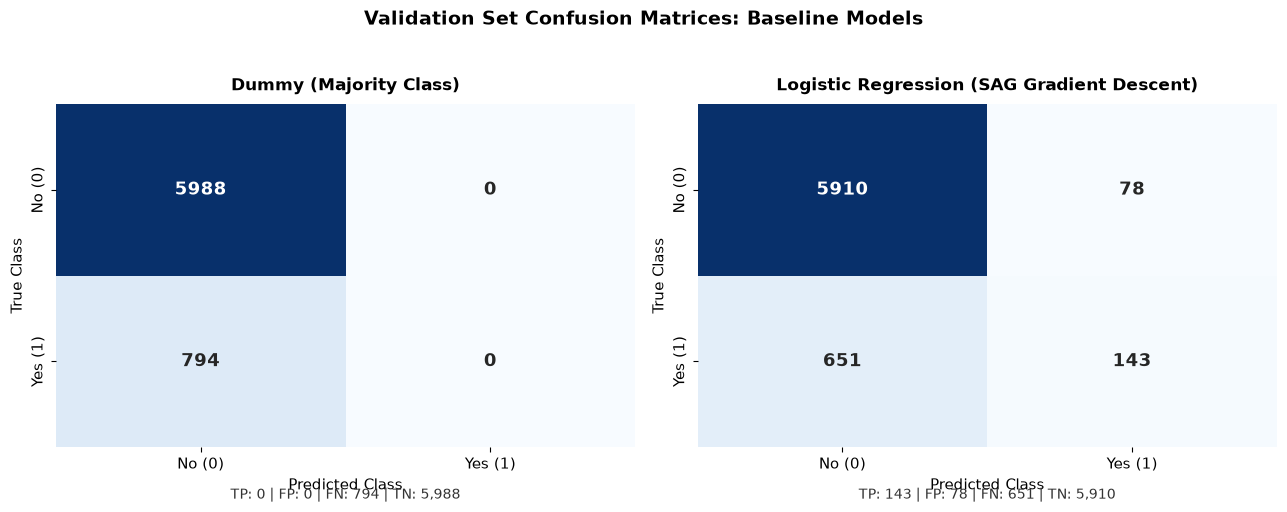

In [14]:
# 3.3 Baseline Model Evaluation on Validation Set
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Compile Quantitative Comparative Table (Accuracy, Precision, Recall, F1 for positive class)
baseline_models = {
    "Majority-Class Dummy": y_val_pred_dummy,
    "Logistic Regression (SAG Gradient Descent)": y_val_pred_lr
}

metrics_list = []
for name, y_pred in baseline_models.items():
    metrics_list.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision (pos)": precision_score(y_val, y_pred, zero_division=0),
        "Recall (pos)": recall_score(y_val, y_pred, zero_division=0),
        "F1-score (pos)": f1_score(y_val, y_pred, zero_division=0)
    })

baseline_comparison_df = pd.DataFrame(metrics_list)
print("=== Baseline Performance Metrics on Validation Set ===")
display(baseline_comparison_df.style.format({
    "Accuracy": "{:.2%}",
    "Precision (pos)": "{:.2%}",
    "Recall (pos)": "{:.2%}",
    "F1-score (pos)": "{:.4f}"
}).background_gradient(subset=["Accuracy", "Precision (pos)", "Recall (pos)", "F1-score (pos)"], cmap="Blues"))

# 2. Confusion Matrix Visualizations (Side-by-side comparison)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
titles = [
    "Dummy (Majority Class)",
    "Logistic Regression (SAG Gradient Descent)"
]

for ax, (name, y_pred), title in zip(axes, baseline_models.items(), titles):
    cm = confusion_matrix(y_val, y_pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        annot_kws={"size": 13, "weight": "bold"},
        xticklabels=["No (0)", "Yes (1)"],
        yticklabels=["No (0)", "Yes (1)"]
    )
    ax.set_title(title, fontsize=12, pad=10, weight="bold")
    ax.set_xlabel("Predicted Class", fontsize=11)
    ax.set_ylabel("True Class", fontsize=11)
    
    tn, fp, fn, tp = cm.ravel()
    ax.text(0.5, -0.15, f"TP: {tp:,} | FP: {fp:,} | FN: {fn:,} | TN: {tn:,}", 
            transform=ax.transAxes, ha='center', fontsize=10, color="#333333")

plt.suptitle("Validation Set Confusion Matrices: Baseline Models", fontsize=14, weight="bold", y=1.03)
plt.tight_layout()
plt.show()


### 3.4 Interpretation of Baseline Results

#### 1. Baseline Performance Summary

| Model | Accuracy | Precision (pos) | Recall (pos) | F1-score (pos) |
|---|:---:|:---:|:---:|:---:|
| **Majority-Class Dummy** | 88.29% | 0.00% | 0.00% | 0.0000 |
| **Logistic Regression (SAG, $\tau=0.5$)** | 89.25% | 64.71% | 18.01% | 0.2818 |

---

#### 2. Key Findings & Class Imbalance Impact

- **The Accuracy Paradox (Dummy Classifier):**
  - Predicting the majority class (`'no'`) yields a deceptively high **88.29% accuracy**, but **0.00% recall and 0.00% precision**—it misses every single subscriber ($TP = 0, FN = 794$). This proves that accuracy is uninformative for imbalanced data.

- **Recall Deficit in Logistic Regression:**
  - Standard Logistic Regression achieves **89.25% accuracy** and moderate precision (**64.71%**), but suffers a severe **recall deficit of only 18.01%**.
  - It detects only 143 subscribers while missing 651 ($FN = 651$, an **81.99% missed opportunity rate**), dragging down the $F_1$-score to **0.2818**.

- **Why Class Imbalance Distorts Gradient Descent:**
  - Because 88.3% of the training data is negative, majority-class non-subscribers generate the overwhelming majority of the gradient force. Standard gradient descent naturally drives predicted probabilities downward, stranding over 81% of actual subscribers below the conventional 0.5 decision threshold.

---

#### 3. Limitations of Linear Baselines & Targets for Part IV

- **Linear Decision Boundary:**
  - Logistic Regression is fundamentally a linear model that can only separate classes using a flat hyperplane ($\mathbf{w}^T \mathbf{x} + b = 0$). It cannot model non-linear relationships (such as the U-shaped conversion curve of client age) or complex multi-feature interactions.

- **Required Performance Targets for Deep Neural Networks (Part IV):**
  To justify the complexity of Deep Neural Networks, the upcoming feed-forward architectures (NNs) equipped with non-linear activation functions (ReLU) and class-imbalance mitigation must be **considerably better** across all evaluation metrics:
  - **Recall:** Must be **considerably higher** than the baseline **18.01%** to drastically cut down missed business opportunities.
  - **F1-Score:** Must be **considerably improved** over the baseline **0.2818** to demonstrate a balanced and effective classifier.

---
## Part IV – Deep Neural Network Design

### Section A: Model Design and Optimization

#### Controlled Single-Variable Experimental Protocol (OFAT)
To systematically optimize our feed-forward neural network without confounding interacting hyperparameters, we apply an **isolated One-Factor-At-A-Time (OFAT) progression**:
1. **Phase 1: Architecture Capacity (Width & Depth)** – Calibrate the hypothesis space geometry first under standard neutral defaults (`ReLU`, `He Normal`, `Adam`).
   - **Step 1.A:** Base Width Calibration ($1 \times$, $2 \times$, $3 \times D_{in}$ on 1 hidden layer).
   - **Step 1.B:** Depth Scaling (1 to 4 hidden layers via compressive funnel).
2. **Phase 2: Activation Functions** – Test `ReLU`, `ELU`, and `Tanh` on the selected architecture to evaluate vanishing gradient and dead neuron dynamics.
3. **Phase 3: Optimization Dynamics & Learning Rates** – Systematically compare classical vs. modern optimizers (`SGD`, `SGD + Momentum`, `RMSprop`, `Adam`) across varying learning rates ($10^{-2}, 10^{-3}, 10^{-4}$).
4. **Phase 4: Regularization & Generalization** – Calibrate L2 weight decay, Dropout rates, and Early Stopping patience to minimize generalization error.
5. **Phase 5 (Part IV.B & Part V.A): Class Imbalance Mitigation & Decision Threshold Tuning** – Compare loss weighting (`class_weight='balanced'`) and optimize the classification decision threshold $\tau^*$ on the validation set before final held-out testing.

> **Why We Evaluate with `ROC-AUC` and `PR-AUC`:**
> - **What it is:** The **ROC** (*Receiver Operating Characteristic*) curve plots True Positive Rate (**Recall**) against False Positive Rate across *all* possible decision thresholds $\tau \in [0, 1]$. **AUC** (*Area Under the Curve*) summarizes this into a single score from `0.5` (random guessing) to `1.0` (perfect ranking)—representing the probability that the model scores a random subscriber higher than a random non-subscriber.
> - **Why we use it:** Because only `11.7%` of clients subscribe, standard accuracy (`~89%`) and metrics fixed at $\tau = 0.50$ can mask improvements or overfitting. `ROC-AUC` is **threshold-independent**, allowing fair comparison of model quality before we optimize $\tau^*$ in Phase 5.


In [15]:
# ===================================================================
# 4.A.1 Modular Setup: Basic NN Trainer & Comparison Utilities
# ===================================================================
from sklearn.metrics import average_precision_score

experiment_registry = {}

def _eval_split(y_true, y_proba):
    """Computes classification and ranking metrics at default threshold tau=0.5."""
    y_pred = (y_proba >= 0.5).astype(int)
    return {
        'Acc': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1-score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_proba),
        'PR-AUC': average_precision_score(y_true, y_proba)
    }

def train_basic_nn(name, hidden_units=[48], activation='relu', kernel_initializer='he_normal',
                    l1_reg=0.0, l2_reg=0.0, dropout_rate=0.0, use_batchnorm=False,
                    early_stopping=False, monitor='val_pr_auc', patience=10,
                    optimizer=None, X_tr=None, y_tr=None, class_weight=None,
                    loss='binary_crossentropy', epochs=40, batch_size=64):
    """Trains a feed-forward NN with optional BatchNorm, L1/L2, Dropout, and EarlyStopping."""
    keras.utils.set_random_seed(42)
    reg = regularizers.l1(l1_reg) if l1_reg > 0 else (regularizers.l2(l2_reg) if l2_reg > 0 else None)
    
    # 1. Model architecture: input -> (Dense -> [BatchNorm] -> Activation -> [Dropout]) -> Sigmoid
    model = keras.Sequential([layers.Input(shape=(X_train.shape[1],))])
    for u in hidden_units:
        if use_batchnorm:
            model.add(layers.Dense(u, use_bias=False, kernel_initializer=kernel_initializer, kernel_regularizer=reg))
            model.add(layers.BatchNormalization())
            model.add(layers.Activation(activation))
        else:
            model.add(layers.Dense(u, activation=activation, kernel_initializer=kernel_initializer, kernel_regularizer=reg))
        if dropout_rate > 0:
            model.add(layers.Dropout(dropout_rate))
    model.add(layers.Dense(1, activation='sigmoid'))
    
    # 2. Optimizer and metrics (tracking both ROC-AUC and PR-AUC)
    model.compile(
        optimizer=optimizer if optimizer is not None else optimizers.Adam(learning_rate=1e-3),
        loss=loss,
        metrics=['accuracy', keras.metrics.AUC(name='roc_auc'), keras.metrics.AUC(curve='PR', name='pr_auc')]
    )
    
    X_fit = X_train if X_tr is None else X_tr
    y_fit = y_train if y_tr is None else y_tr
    # 3. Train (with optional Early Stopping restoring best weights)
    cb = []
    if early_stopping:
        mode = 'max' if 'auc' in monitor else 'min'
        cb.append(callbacks.EarlyStopping(monitor=monitor, mode=mode, patience=patience, restore_best_weights=True))
    h = model.fit(
        X_fit, y_fit,
        class_weight=class_weight,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=cb,
        verbose=0
    )
    
    # 4. Predictions & Metrics for both Train and Validation (at default tau = 0.5)
    y_train_proba = model.predict(X_fit, verbose=0).ravel()
    y_val_proba = model.predict(X_val, verbose=0).ravel()
    
    base_info = {
        'Experiment': name,
        'Architecture': str(hidden_units),
        'Parameters': model.count_params(),
        'Epochs': len(h.history['loss'])
    }
    train_metrics = {**base_info, 'Loss (Final)': h.history['loss'][-1], 'Loss (Min)': min(h.history['loss']), **_eval_split(y_fit, y_train_proba)}
    val_metrics   = {**base_info, 'Loss (Final)': h.history['val_loss'][-1], 'Loss (Min)': min(h.history['val_loss']), **_eval_split(y_val, y_val_proba)}
    
    experiment_registry[name] = {
        'model': model,
        'history': h.history,
        'train_metrics': train_metrics,
        'val_metrics': val_metrics,
        'metrics': val_metrics,
        'y_val_proba': y_val_proba
    }
    return val_metrics

def compare_and_plot(exp_names, title='Learning Curves'):
    """Displays Training & Validation metric tables and a 2x2 grid of separate Train/Val curves."""
    fmt = {
        'Parameters': '{:,}',
        'Loss (Final)': '{:.4f}',
        'Loss (Min)': '{:.4f}',
        'Acc': '{:.2%}',
        'Precision': '{:.2%}',
        'Recall': '{:.2%}',
        'F1-score': '{:.4f}',
        'ROC-AUC': '{:.4f}',
        'PR-AUC': '{:.4f}'
    }
    
    for split_label, key in [('Training Set Metrics', 'train_metrics'), ('Validation Set Metrics', 'val_metrics')]:
        df_split = pd.DataFrame([experiment_registry[n][key] for n in exp_names if n in experiment_registry])
        print(f'--- {split_label} ---')
        display(df_split.style.format(fmt).highlight_min(subset=['Loss (Min)'], color='#d4edda')
                              .highlight_max(subset=['F1-score', 'ROC-AUC', 'PR-AUC'], color='#d4edda'))
    
    # 2x2 grid: separate subplots for Training Loss, Validation Loss, Training AUC, Validation AUC
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    colors = plt.cm.tab10(np.linspace(0, 1, max(len(exp_names), 3)))
    
    for idx, n in enumerate(exp_names):
        if n not in experiment_registry: continue
        h = experiment_registry[n]['history']
        epochs = range(1, len(h['loss']) + 1)
        c = colors[idx]
        
        axes[0, 0].plot(epochs, h['loss'], color=c, lw=1.8, label=n)
        axes[0, 1].plot(epochs, h['val_loss'], color=c, lw=2.0, label=n)
        axes[1, 0].plot(epochs, h['roc_auc'], color=c, lw=1.8, label=n)
        axes[1, 1].plot(epochs, h['val_roc_auc'], color=c, lw=2.0, label=n)
        
    plot_configs = [
        (axes[0, 0], 'Training Loss (Total Objective)', 'Loss'),
        (axes[0, 1], 'Validation Loss (Total Objective)', 'Loss'),
        (axes[1, 0], 'Training ROC-AUC', 'ROC-AUC'),
        (axes[1, 1], 'Validation ROC-AUC', 'ROC-AUC')
    ]
    
    for ax, t, yl in plot_configs:
        ax.set_title(t, fontweight='bold', fontsize=11)
        ax.set_xlabel('Epoch')
        ax.set_ylabel(yl)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8, loc='best')
        
    plt.suptitle(title, fontsize=13, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()

print('Setup complete: Train & Val tables (with PR-AUC) + 2x2 grid configured.')

Setup complete: Train & Val tables (with PR-AUC) + 2x2 grid configured.


#### Step 1.A: Base Width Calibration (1 Hidden Layer: [48], [72], [96], [144])
We evaluate single-hidden-layer widths (`[48]`, `[72]`, `[96]`, `[144]`) around our input dimension $D_{in} = 51$ to isolate the bias-variance trade-off on initial representation capacity.

> *Note on width choices:* Earlier preprocessing produced `48` features (`1.0×`, `1.5×`, `2.0×`, `3.0×` = `[48, 72, 96, 144]`). After adding cyclical `sin`/`cos` encodings (`+3` net features $\to D_{in} = 51$), we retained the same `[48, 72, 96, 144]` grid (`~0.94×` to `2.82×` of $D_{in} = 51$) because it forms a clean `24`-unit progression and ensures `72` divides evenly across deeper funnel layers (`72 -> 36 -> 18 -> 9`).

=== Executing Step 1.A: Base Width Calibration ===


--- Training Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Width_48,[48],"2,545",40,0.2669,0.2669,90.30%,69.85%,30.04%,0.4201,0.8407,0.5238
1,Width_72,[72],"3,817",40,0.2599,0.2599,90.59%,71.45%,32.58%,0.4475,0.8531,0.5535
2,Width_96,[96],"5,089",40,0.2571,0.2571,90.68%,73.78%,31.55%,0.4420,0.8580,0.5658
3,Width_144,[144],"7,633",40,0.2475,0.2475,91.11%,77.30%,34.04%,0.4726,0.8746,0.6019


--- Validation Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Width_48,[48],"2,545",40,0.2888,0.2850,89.56%,63.61%,25.31%,0.3622,0.7937,0.4408
1,Width_72,[72],"3,817",40,0.2901,0.2830,89.68%,63.91%,27.20%,0.3816,0.7929,0.4397
2,Width_96,[96],"5,089",40,0.2939,0.2844,89.60%,63.69%,26.07%,0.3700,0.7881,0.4251
3,Width_144,[144],"7,633",40,0.2965,0.2851,89.37%,61.23%,25.06%,0.3557,0.7833,0.4284


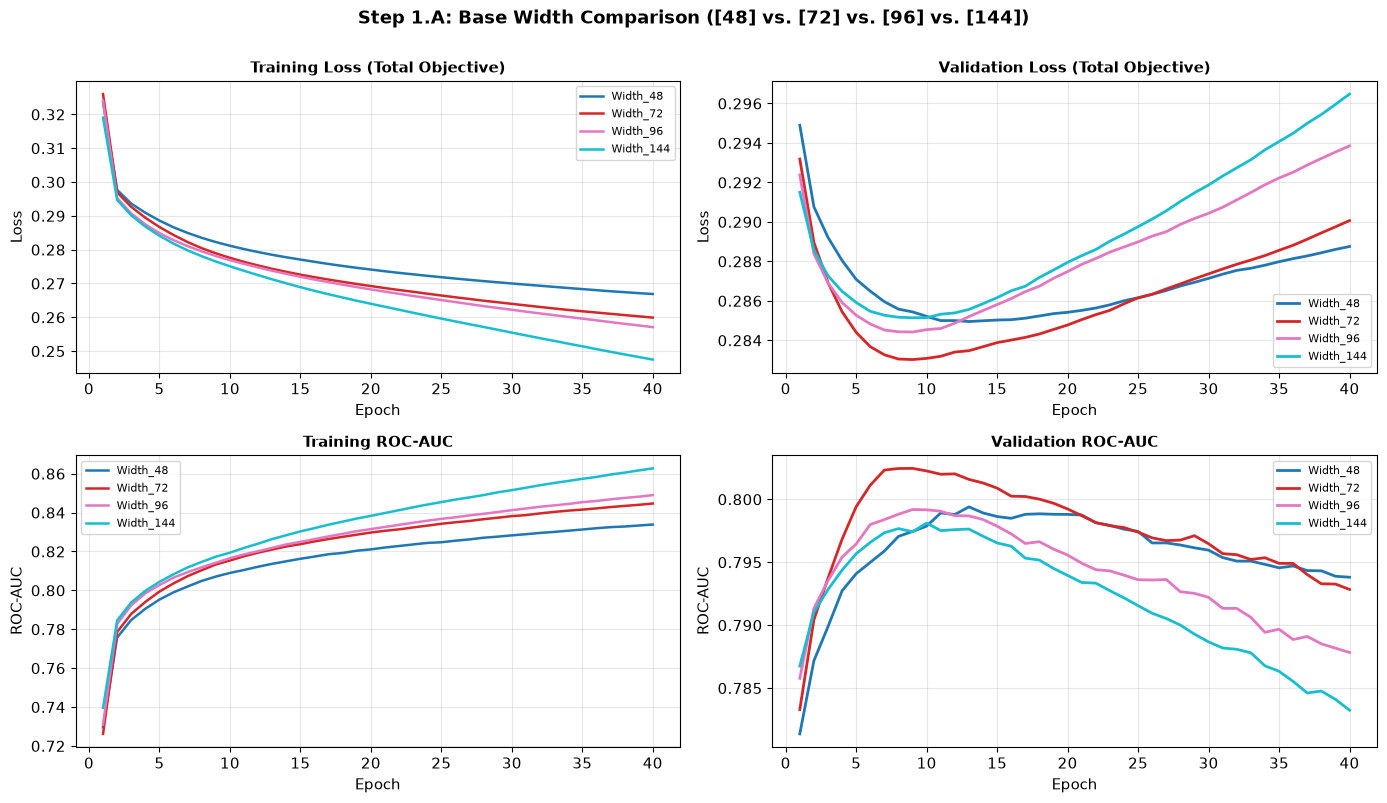

In [16]:
# ===================================================================
# Step 1.A Execution: Base Width Calibration
# ===================================================================
print('=== Executing Step 1.A: Base Width Calibration ===')
for w in [48, 72, 96, 144]:
    train_basic_nn(f'Width_{w}', hidden_units=[w], epochs=40)

step_1a_models = ['Width_48', 'Width_72', 'Width_96', 'Width_144']
compare_and_plot(step_1a_models, title='Step 1.A: Base Width Comparison ([48] vs. [72] vs. [96] vs. [144])')


#### Step 1.A (Regularized): Base Width Calibration with $L_2$ Weight Decay ($\lambda = 10^{-3}$)
To test whether wider layers only failed due to unregularized overfitting, we repeat **Step 1.A** identically with an $L_2$ kernel penalty ($\lambda = 10^{-3}$).

=== Executing Step 1.A (L2 Regularized): Base Width Calibration ===


--- Training Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Width_48_L2,[48],"2,545",40,0.2884,0.2884,89.72%,69.18%,21.83%,0.3318,0.8154,0.4763
1,Width_72_L2,[72],"3,817",40,0.2882,0.2882,89.70%,69.79%,21.10%,0.3240,0.8196,0.4800
2,Width_96_L2,[96],"5,089",40,0.2878,0.2878,89.73%,69.55%,21.72%,0.3310,0.8202,0.4833
3,Width_144_L2,[144],"7,633",40,0.2875,0.2875,89.76%,69.86%,21.85%,0.3329,0.8202,0.4844


--- Validation Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Width_48_L2,[48],"2,545",40,0.2908,0.2908,89.65%,67.97%,21.91%,0.3314,0.8021,0.4589
1,Width_72_L2,[72],"3,817",40,0.2910,0.2908,89.68%,69.75%,20.91%,0.3217,0.8020,0.4618
2,Width_96_L2,[96],"5,089",40,0.2915,0.2911,89.75%,70.20%,21.66%,0.3311,0.8007,0.4628
3,Width_144_L2,[144],"7,633",40,0.2925,0.2918,89.74%,70.25%,21.41%,0.3282,0.7979,0.4631


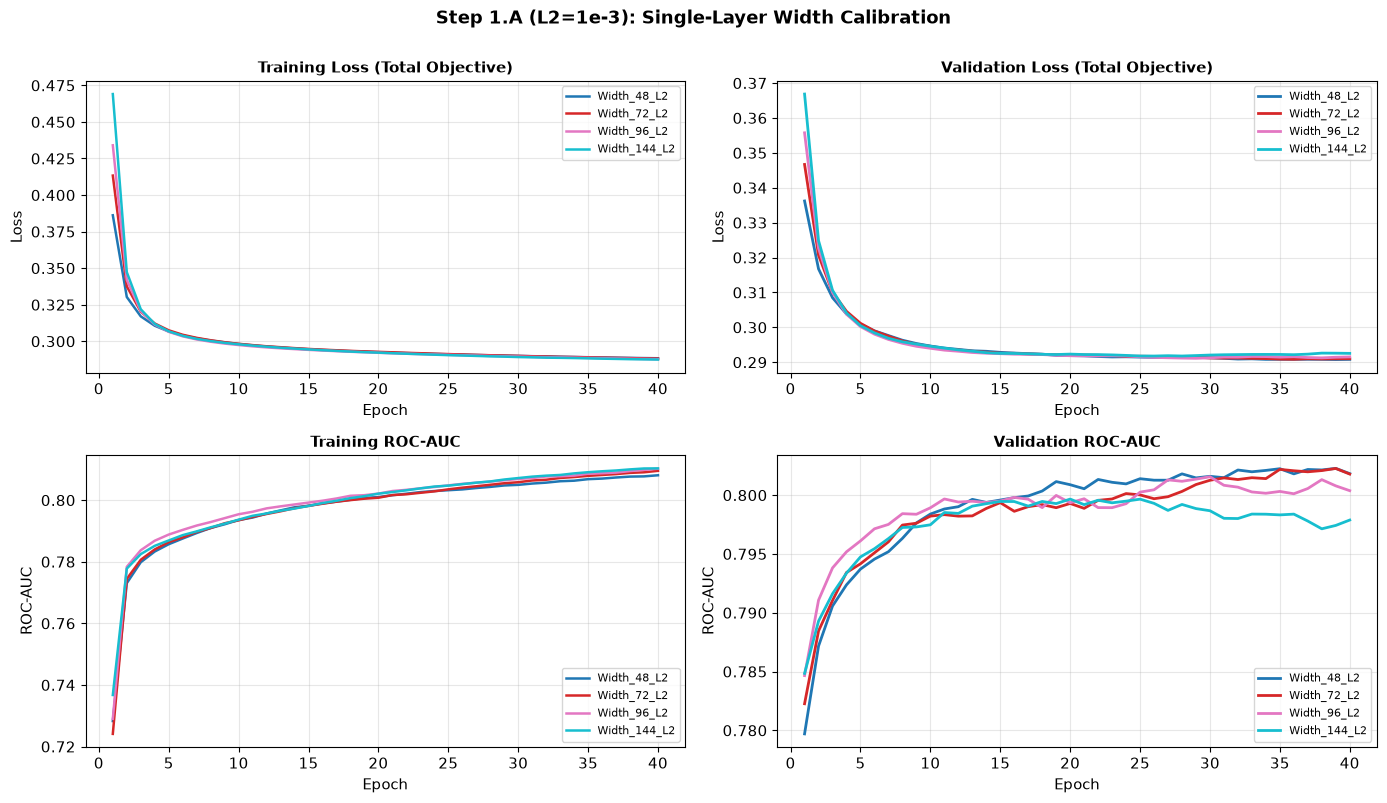

In [17]:
# ===================================================================
# Step 1.A (L2): Base Width Calibration with Weight Decay (1e-3)
# ===================================================================
print("=== Executing Step 1.A (L2 Regularized): Base Width Calibration ===")
width_l2_exps = []
for w in [48, 72, 96, 144]:
    name = f"Width_{w}_L2"
    train_basic_nn(name, hidden_units=[w], l2_reg=1e-3, epochs=40)
    width_l2_exps.append(name)

compare_and_plot(width_l2_exps, title="Step 1.A (L2=1e-3): Single-Layer Width Calibration")


#### Step 1.B: Network Depth & Geometry (Compressive Funnel vs. Constant Width across 1 to 4 Layers)
- Anchoring on $W^* = 72$, we scale network depth across 1, 2, 3, and 4 layers to evaluate two architectural geometries:
  1. **Compressive Funnel (Pyramid):** $[72]$, $[72, 36]$, $[72, 36, 18]$, $[72, 36, 18, 9]$ (hierarchical dimensionality reduction).
  2. **Constant Width (Cylinder):** $[72]$, $[72, 72]$, $[72, 72, 72]$, $[72, 72, 72, 72]$ (uniform width without compression).
- **Objective:** Systematically isolate how depth and geometric compression govern representation capacity, parameter explosion, and generalization stability on tabular data.


=== Executing Step 1.B: Depth & Geometry Calibration (1 to 4 Layers) ===


--- Training Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,1L_Base,[72],"3,817",40,0.2599,0.2599,90.59%,71.45%,32.58%,0.4475,0.8531,0.5535
1,2L_Funnel,"[72, 36]","6,409",40,0.2310,0.2310,91.79%,79.00%,40.65%,0.5368,0.8900,0.6530
2,2L_Constant,"[72, 72]","9,073",40,0.2136,0.2136,92.05%,82.86%,40.36%,0.5428,0.9085,0.6853
3,3L_Funnel,"[72, 36, 18]","7,057",40,0.2082,0.2082,92.29%,78.47%,46.97%,0.5877,0.8944,0.6719
4,3L_Constant,"[72, 72, 72]","14,329",40,0.1488,0.1488,93.02%,87.96%,46.76%,0.6106,0.9227,0.7423
5,4L_Funnel,"[72, 36, 18, 9]","7,219",40,0.1987,0.1987,92.07%,77.08%,45.87%,0.5751,0.9066,0.6728
6,4L_Constant,"[72, 72, 72, 72]","19,585",40,0.1170,0.1165,92.99%,76.84%,57.35%,0.6568,0.9121,0.7214


--- Validation Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,1L_Base,[72],"3,817",40,0.2901,0.2830,89.68%,63.91%,27.20%,0.3816,0.7929,0.4397
1,2L_Funnel,"[72, 36]","6,409",40,0.3198,0.2852,88.69%,53.49%,26.07%,0.3506,0.7698,0.3840
2,2L_Constant,"[72, 72]","9,073",40,0.3413,0.2855,89.13%,57.85%,26.45%,0.3630,0.7425,0.3699
3,3L_Funnel,"[72, 36, 18]","7,057",40,0.3729,0.2864,88.37%,50.54%,29.60%,0.3733,0.7320,0.3606
4,3L_Constant,"[72, 72, 72]","14,329",40,0.4704,0.2856,88.66%,53.00%,27.83%,0.3650,0.7120,0.3499
5,4L_Funnel,"[72, 36, 18, 9]","7,219",40,0.4015,0.2850,88.50%,51.63%,27.96%,0.3627,0.7317,0.3580
6,4L_Constant,"[72, 72, 72, 72]","19,585",40,0.7590,0.2882,86.38%,38.18%,26.45%,0.3125,0.6527,0.2737


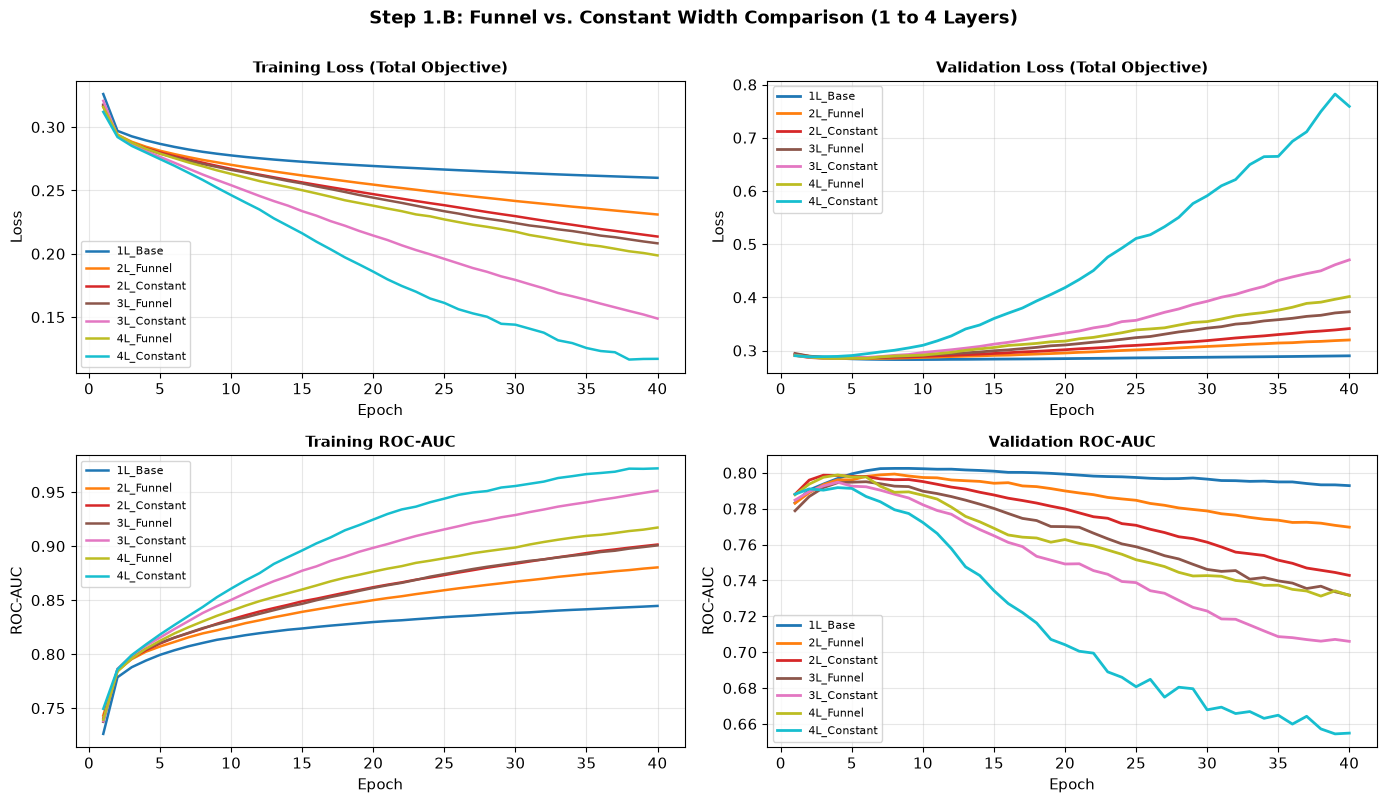

In [18]:
# ===================================================================
# Step 1.B Execution: Funnel vs. Constant Width across 1 to 4 Layers
# ===================================================================
print('=== Executing Step 1.B: Depth & Geometry Calibration (1 to 4 Layers) ===')
depth_architectures = {
    '1L_Base': [72],
    '2L_Funnel': [72, 36],
    '2L_Constant': [72, 72],
    '3L_Funnel': [72, 36, 18],
    '3L_Constant': [72, 72, 72],
    '4L_Funnel': [72, 36, 18, 9],
    '4L_Constant': [72, 72, 72, 72]
}

for name, units in depth_architectures.items():
    train_basic_nn(name, hidden_units=units, epochs=40)

step_1b_models = list(depth_architectures.keys())
compare_and_plot(step_1b_models, title='Step 1.B: Funnel vs. Constant Width Comparison (1 to 4 Layers)')


#### Step 1.B (Regularized): Depth & Geometry with $L_2$ Weight Decay ($\lambda = 10^{-3}$)
We repeat **Step 1.B** identically with $L_2 = 10^{-3}$ across all 1-to-4 layer Funnel and Constant architectures to verify whether deeper networks outperform shallow baselines once weight growth is constrained.

=== Executing Step 1.B (L2 Regularized): Depth & Geometry ===


--- Training Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,1L_Base_L2,[72],"3,817",40,0.2882,0.2882,89.70%,69.79%,21.10%,0.3240,0.8196,0.4800
1,2L_Funnel_L2,"[72, 36]","6,409",40,0.2872,0.2872,89.75%,68.71%,22.72%,0.3415,0.8203,0.4855
2,2L_Constant_L2,"[72, 72]","9,073",40,0.2873,0.2873,89.73%,68.73%,22.45%,0.3384,0.8197,0.4831
3,3L_Funnel_L2,"[72, 36, 18]","7,057",40,0.2899,0.2899,89.68%,67.90%,22.29%,0.3356,0.8172,0.4827
4,3L_Constant_L2,"[72, 72, 72]","14,329",40,0.2887,0.2887,89.78%,68.76%,23.12%,0.3461,0.8189,0.4838
5,4L_Funnel_L2,"[72, 36, 18, 9]","7,219",40,0.2908,0.2908,89.78%,69.44%,22.58%,0.3408,0.8196,0.4863
6,4L_Constant_L2,"[72, 72, 72, 72]","19,585",40,0.2900,0.2900,89.82%,68.26%,24.23%,0.3577,0.8194,0.4848


--- Validation Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,1L_Base_L2,[72],"3,817",40,0.2910,0.2908,89.68%,69.75%,20.91%,0.3217,0.8020,0.4618
1,2L_Funnel_L2,"[72, 36]","6,409",40,0.2916,0.2916,89.59%,66.79%,22.04%,0.3314,0.8005,0.4634
2,2L_Constant_L2,"[72, 72]","9,073",40,0.2924,0.2920,89.56%,66.67%,21.66%,0.3270,0.7989,0.4621
3,3L_Funnel_L2,"[72, 36, 18]","7,057",40,0.2915,0.2915,89.71%,67.91%,22.92%,0.3427,0.8045,0.4641
4,3L_Constant_L2,"[72, 72, 72]","14,329",40,0.2930,0.2929,89.71%,68.75%,22.17%,0.3352,0.7988,0.4633
5,4L_Funnel_L2,"[72, 36, 18, 9]","7,219",40,0.2949,0.2949,89.80%,70.24%,22.29%,0.3384,0.8015,0.4671
6,4L_Constant_L2,"[72, 72, 72, 72]","19,585",40,0.2937,0.2937,89.58%,66.29%,22.29%,0.3336,0.8021,0.4577


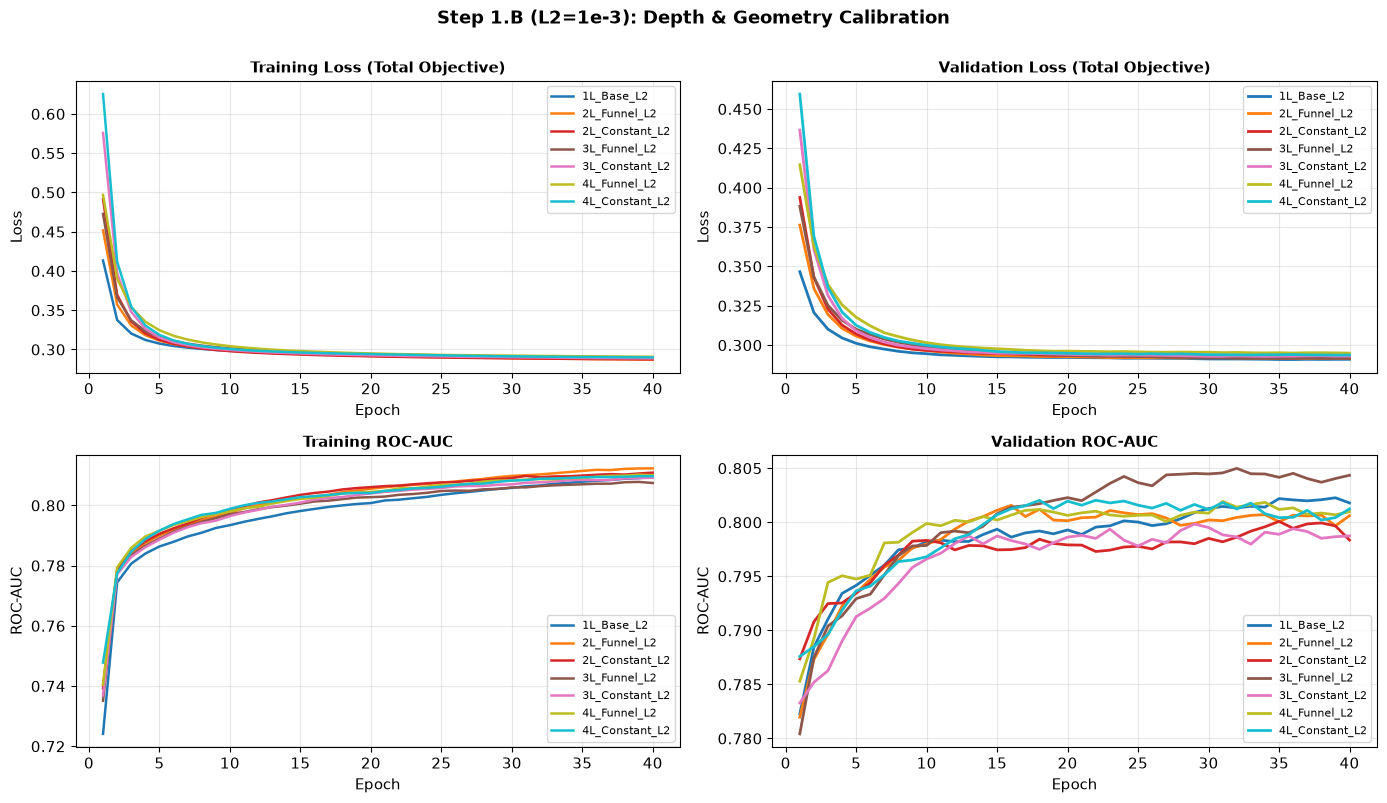

In [19]:
# ===================================================================
# Step 1.B (L2): Depth & Geometry Calibration with Weight Decay (1e-3)
# ===================================================================
print("=== Executing Step 1.B (L2 Regularized): Depth & Geometry ===")
depth_l2_configs = [
    ("1L_Base_L2",     [72]),
    ("2L_Funnel_L2",   [72, 36]),
    ("2L_Constant_L2", [72, 72]),
    ("3L_Funnel_L2",   [72, 36, 18]),
    ("3L_Constant_L2", [72, 72, 72]),
    ("4L_Funnel_L2",   [72, 36, 18, 9]),
    ("4L_Constant_L2", [72, 72, 72, 72]),
]
depth_l2_exps = []
for name, units in depth_l2_configs:
    train_basic_nn(name, hidden_units=units, l2_reg=1e-3, epochs=40)
    depth_l2_exps.append(name)

compare_and_plot(depth_l2_exps, title="Step 1.B (L2=1e-3): Depth & Geometry Calibration")


#### 1.C Summary of Phase 1 Findings: Capacity, Geometry & Architecture Selection

1. **Compressive Funnel Networks Are Superior to Constant-Width Networks:**
   - Across both unregularized and regularized experiments, **Funnel architectures (`72 -> 36 -> 18 ...`) outperform Constant-width architectures (`72 -> 72 -> 72 ...`)** in parameter efficiency and generalization stability.
   - **Empirical Evidence:** At 3 and 4 layers, Constant-width models more than double the parameter budget (`14,329` and `19,585` weights) without improving signal extraction. Without regularization, `4L_Constant` overfits severely (Training Loss `0.1170` vs. Validation Loss exploding to `0.7590`, ROC-AUC collapsing to `0.6527`). Once $L_2$ regularization tames overfitting, `3L_Funnel_L2` outperforms `3L_Constant_L2` across `ROC-AUC` (`0.8045` vs. `0.7988`), `PR-AUC` (`0.4641` vs. `0.4633`), and `F1-score` (`0.3427` vs. `0.3352`) using less than half the parameters.

2. **Two-Stage Evaluation Methodology (Unregularized Diagnosis $\to$ Regularized Generalization):**
   - **Stage 1 — Without Regularization:** Shallow `[72]` stays relatively stable (`0.2830` min val loss), while deeper architectures quickly memorize training noise after Epoch 5 (`3L_Funnel` drops to `ROC-AUC = 0.7320` by Epoch 40).
   - **Stage 2 — With $L_2$ Weight Decay ($\lambda = 10^{-3}$):** Constraining weights eliminates late-epoch validation drift and lifts `3L_Funnel` `ROC-AUC` from `0.7320` to **`0.8045`**.

3. **Selected Architecture for Subsequent Phases: `3L_Funnel` (`[72, 36, 18]`):**
   - **Parameter Efficiency:** Uses **7,057 parameters** (less than half of `3L_Constant`'s `14,329`).
   - **Strongest Overall Validation Metrics:** Under $L_2 = 10^{-3}$, it achieves **`ROC-AUC = 0.8045`**, **`PR-AUC = 0.4641`**, **`F1-score = 0.3427`**, and **Min Validation Loss = `0.2915`** with zero drift over 40 epochs.

---
#### Phase 2: Activation Functions (`ReLU` vs. `ELU` vs. `Tanh`)
On our selected **`3L_Funnel` (`[72, 36, 18]`)** scaffold (with `Adam(1e-3)` and $L_2 = 10^{-3}$ held constant), we compare:
- **`ReLU` + `he_normal`**: Piecewise linear $[0, \infty)$, constant gradient $= 1$ for active units, fast convergence.
- **`ELU` + `he_normal`**: Smooth negative tail ($e^z - 1$ for $z < 0$), prevents dying neurons and shifts mean activations closer to zero.
- **`Tanh` + `glorot_normal` (Xavier Normal)**: Zero-centered and bounded $(-1, 1)$, smooth saturating gradients.

=== Executing Phase 2: Activation Functions on 3L_Funnel [72, 36, 18] ===


--- Training Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,3L_ReLU_He,"[72, 36, 18]","7,057",40,0.2899,0.2899,89.68%,67.90%,22.29%,0.3356,0.8172,0.4827
1,3L_ELU_He,"[72, 36, 18]","7,057",40,0.2998,0.2998,89.34%,67.48%,17.15%,0.2735,0.7920,0.4299
2,3L_Tanh_Xavier,"[72, 36, 18]","7,057",40,0.3005,0.3005,89.33%,66.43%,17.75%,0.2801,0.7878,0.4276


--- Validation Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,3L_ReLU_He,"[72, 36, 18]","7,057",40,0.2915,0.2915,89.71%,67.91%,22.92%,0.3427,0.8045,0.4641
1,3L_ELU_He,"[72, 36, 18]","7,057",40,0.2961,0.2961,89.59%,70.95%,18.77%,0.2968,0.7899,0.4497
2,3L_Tanh_Xavier,"[72, 36, 18]","7,057",40,0.2958,0.2958,89.66%,71.43%,19.52%,0.3066,0.7899,0.4433


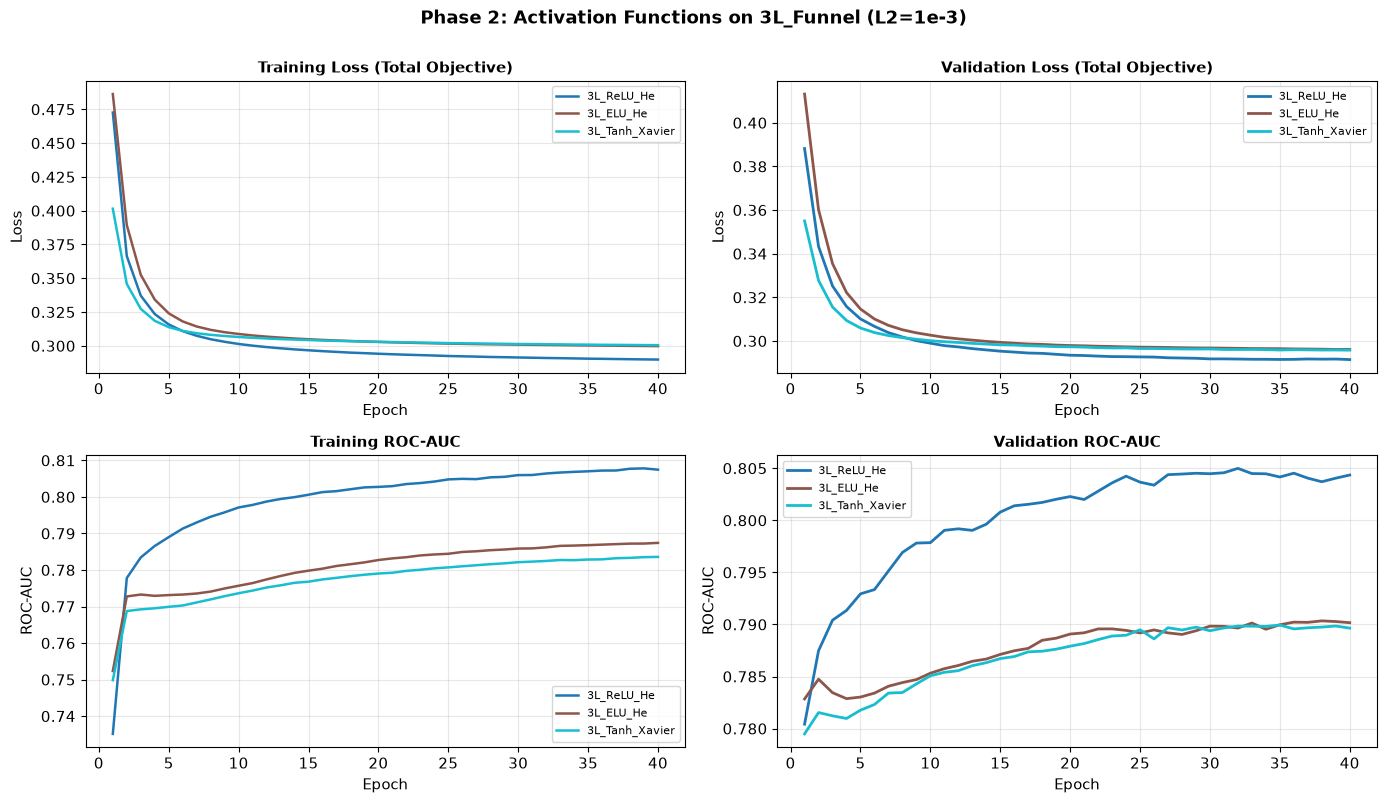

In [20]:
# ===================================================================
# Phase 2: Activation Functions (ReLU+He vs. ELU+He vs. Tanh+Xavier)
# ===================================================================
print("=== Executing Phase 2: Activation Functions on 3L_Funnel [72, 36, 18] ===")
act_configs = [
    ("3L_ReLU_He",     "relu", "he_normal"),
    ("3L_ELU_He",      "elu",  "he_normal"),
    ("3L_Tanh_Xavier", "tanh", "glorot_normal"),
]
act_exps = []
for name, act, init in act_configs:
    train_basic_nn(name, hidden_units=[72, 36, 18], activation=act, kernel_initializer=init, l2_reg=1e-3, epochs=40)
    act_exps.append(name)

compare_and_plot(act_exps, title="Phase 2: Activation Functions on 3L_Funnel (L2=1e-3)")


#### Phase 2 Findings: Activation Selection
- **`ReLU` (`he_normal`)** outperforms both **`ELU`** and **`Tanh`** across every key metric—**Recall** (`22.92%` vs. `18.77%` for `ELU` and `19.52%` for `Tanh`), **F1-score** (`0.3427`), **ROC-AUC** (`0.8045`), **PR-AUC** (`0.4641`), and **Validation Loss** (`0.2915`).
- **Weight Initialization:** We paired `he_normal` ($\text{Var}(W) = 2/n_{\text{in}}$) with `ReLU`/`ELU` to preserve gradient variance across layers, and `glorot_normal` with symmetric `Tanh` to prevent early saturation.
- **Choice Moving Forward:** We select **`ReLU` + `he_normal`** on **`3L_Funnel` (`[72, 36, 18]`)** for **Phase 3**.

---
#### Phase 3: Optimization Dynamics & Learning Rates
##### Step 3.A: Optimizer Comparison (`SGD`, `SGD + Momentum`, `RMSprop`, `Adam`)
Holding our winning **`3L_Funnel` (`[72, 36, 18]`)**, **`ReLU` + `he_normal`**, and **$L_2 = 10^{-3}$** fixed, we compare four optimizers over 40 epochs.

=== Executing Step 3.A: Optimizer Comparison ===


--- Training Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Opt_SGD,"[72, 36, 18]","7,057",40,0.4083,0.4083,89.42%,65.61%,20.10%,0.3077,0.8010,0.4485
1,Opt_SGD_Mom,"[72, 36, 18]","7,057",40,0.2932,0.2932,89.74%,70.52%,21.07%,0.3245,0.8171,0.4831
2,Opt_RMSprop,"[72, 36, 18]","7,057",40,0.3032,0.3028,89.65%,65.42%,24.47%,0.3562,0.8101,0.4693
3,Opt_Adam,"[72, 36, 18]","7,057",40,0.2899,0.2899,89.68%,67.90%,22.29%,0.3356,0.8172,0.4827


--- Validation Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Opt_SGD,"[72, 36, 18]","7,057",40,0.4090,0.4090,89.58%,67.76%,20.91%,0.3195,0.7911,0.4418
1,Opt_SGD_Mom,"[72, 36, 18]","7,057",40,0.2962,0.2962,89.50%,67.52%,19.90%,0.3074,0.8026,0.4607
2,Opt_RMSprop,"[72, 36, 18]","7,057",40,0.3051,0.3026,89.63%,65.02%,24.81%,0.3592,0.7974,0.4594
3,Opt_Adam,"[72, 36, 18]","7,057",40,0.2915,0.2915,89.71%,67.91%,22.92%,0.3427,0.8045,0.4641


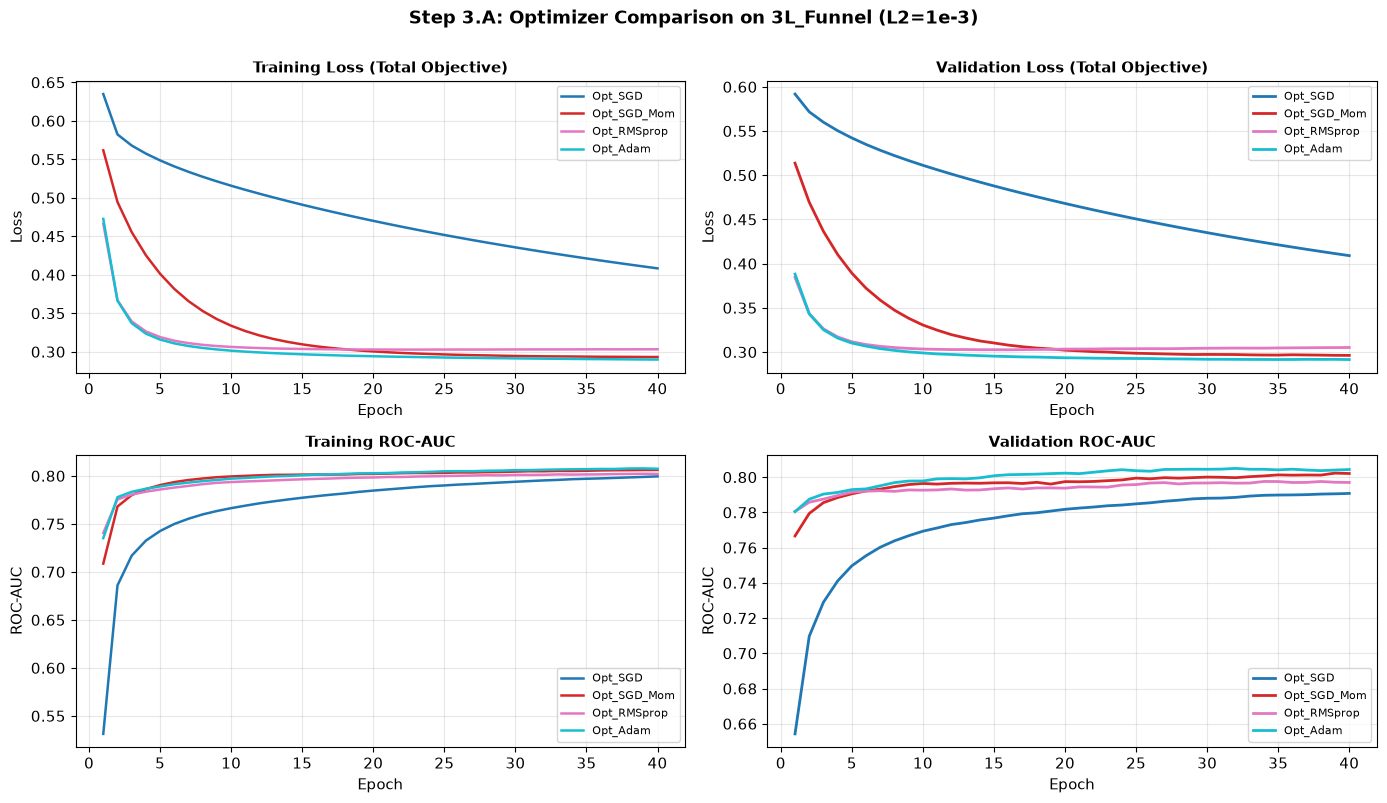

In [21]:
# ===================================================================
# Step 3.A: Optimizer Comparison on 3L_Funnel [72, 36, 18]
# ===================================================================
print("=== Executing Step 3.A: Optimizer Comparison ===")
opt_configs = [
    ("Opt_SGD",      lambda: optimizers.SGD(learning_rate=1e-2)),
    ("Opt_SGD_Mom",  lambda: optimizers.SGD(learning_rate=1e-2, momentum=0.9)),
    ("Opt_RMSprop",  lambda: optimizers.RMSprop(learning_rate=1e-3)),
    ("Opt_Adam",     lambda: optimizers.Adam(learning_rate=1e-3)),
]
opt_exps = []
for name, opt_fn in opt_configs:
    train_basic_nn(name, hidden_units=[72, 36, 18], activation="relu", kernel_initializer="he_normal", l2_reg=1e-3, optimizer=opt_fn(), epochs=40)
    opt_exps.append(name)

compare_and_plot(opt_exps, title="Step 3.A: Optimizer Comparison on 3L_Funnel (L2=1e-3)")


##### Step 3.B: Learning Rate Sweep (`Adam` at `1e-2`, `1e-3`, `1e-4`)
Now we test whether `Adam` benefits from a larger (`1e-2`) or smaller (`1e-4`) step size compared to the default `1e-3`.

=== Executing Step 3.B: Adam Learning Rate Sweep ===


--- Training Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Adam_LR_1e-02,"[72, 36, 18]","7,057",40,0.3069,0.3065,89.31%,68.10%,16.21%,0.2618,0.7807,0.4191
1,Adam_LR_1e-03,"[72, 36, 18]","7,057",40,0.2899,0.2899,89.68%,67.90%,22.29%,0.3356,0.8172,0.4827
2,Adam_LR_1e-04,"[72, 36, 18]","7,057",40,0.3178,0.3178,89.56%,68.06%,20.26%,0.3122,0.8074,0.4598


--- Validation Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Adam_LR_1e-02,"[72, 36, 18]","7,057",40,0.2998,0.2993,89.52%,70.85%,17.76%,0.2840,0.7855,0.4341
1,Adam_LR_1e-03,"[72, 36, 18]","7,057",40,0.2915,0.2915,89.71%,67.91%,22.92%,0.3427,0.8045,0.4641
2,Adam_LR_1e-04,"[72, 36, 18]","7,057",40,0.3201,0.3201,89.60%,68.46%,20.78%,0.3188,0.7959,0.4512


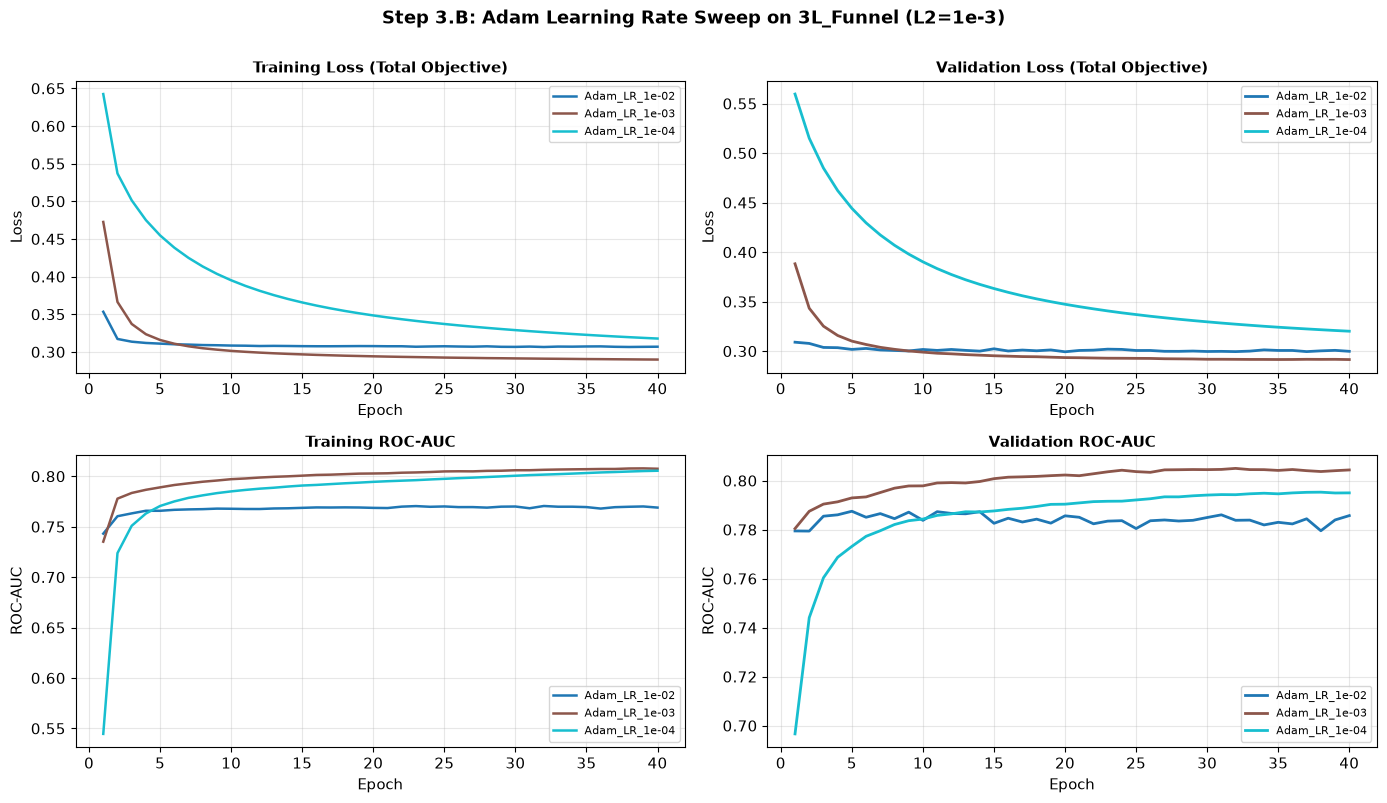

In [22]:
# ===================================================================
# Step 3.B: Learning Rate Sweep (Adam: 1e-2 vs 1e-3 vs 1e-4)
# ===================================================================
print("=== Executing Step 3.B: Adam Learning Rate Sweep ===")
lr_exps = []
for lr in [1e-2, 1e-3, 1e-4]:
    name = f"Adam_LR_{lr:.0e}"
    train_basic_nn(name, hidden_units=[72, 36, 18], activation="relu", kernel_initializer="he_normal", l2_reg=1e-3, optimizer=optimizers.Adam(learning_rate=lr), epochs=40)
    lr_exps.append(name)

compare_and_plot(lr_exps, title="Step 3.B: Adam Learning Rate Sweep on 3L_Funnel (L2=1e-3)")


#### Phase 3 Findings: Optimizer & Learning Rate Selection
- **Optimizer Comparison (`Adam` vs. `RMSprop` vs. `SGD`):**
  - Vanilla `SGD` (`1e-2`) converged slowly (`ROC-AUC = 0.7911`, `Val Loss = 0.4090`), while `SGD + Momentum` closed most of the gap (`ROC-AUC = 0.8026`).
  - **`RMSprop` (`1e-3`)** achieved higher raw Recall (`24.81%`) and `F1-score` (`0.3592`) at $\tau = 0.50$, but with higher validation loss (`0.3026` min $\to$ `0.3051` final) and lower ranking (`ROC-AUC = 0.7974`).
  - **`Adam` (`1e-3`)** achieved the **lowest Validation Loss (`0.2915`)**, zero drift, and top **`ROC-AUC` (`0.8045`)** and **`PR-AUC` (`0.4641`)**.
- **Learning Rate Sweep (`Adam`):** `1e-2` overshot (`ROC-AUC = 0.7855`) and `1e-4` under-converged (`Val Loss = 0.3201`), confirming **`1e-3`** as optimal.
- **Choice Moving Forward:** We retain **`Adam (lr=1e-3)`**.

---
#### Phase 4: Regularization & Generalization
##### Step 4.A: $L_1$ vs. $L_2$ Regularization Comparison
On our **`3L_Funnel` (`[72, 36, 18]`, `ReLU + He`, `Adam(1e-3)`)** configuration, we compare **no regularization**, **$L_1$ (`1e-3`)**, and **$L_2$ (`1e-3`)** to verify which penalty yields stronger generalization.

=== Executing Step 4.A: L1 vs. L2 Regularization ===


--- Training Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,No_Reg,"[72, 36, 18]","7,057",40,0.2082,0.2082,92.29%,78.47%,46.97%,0.5877,0.8944,0.6719
1,L1_1e-3,"[72, 36, 18]","7,057",40,0.3095,0.3095,89.24%,62.63%,19.96%,0.3027,0.7798,0.4159
2,L2_1e-3,"[72, 36, 18]","7,057",40,0.2899,0.2899,89.68%,67.90%,22.29%,0.3356,0.8172,0.4827


--- Validation Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,No_Reg,"[72, 36, 18]","7,057",40,0.3729,0.2864,88.37%,50.54%,29.60%,0.3733,0.7320,0.3606
1,L1_1e-3,"[72, 36, 18]","7,057",40,0.3036,0.3036,89.47%,64.93%,21.91%,0.3277,0.7845,0.4352
2,L2_1e-3,"[72, 36, 18]","7,057",40,0.2915,0.2915,89.71%,67.91%,22.92%,0.3427,0.8045,0.4641


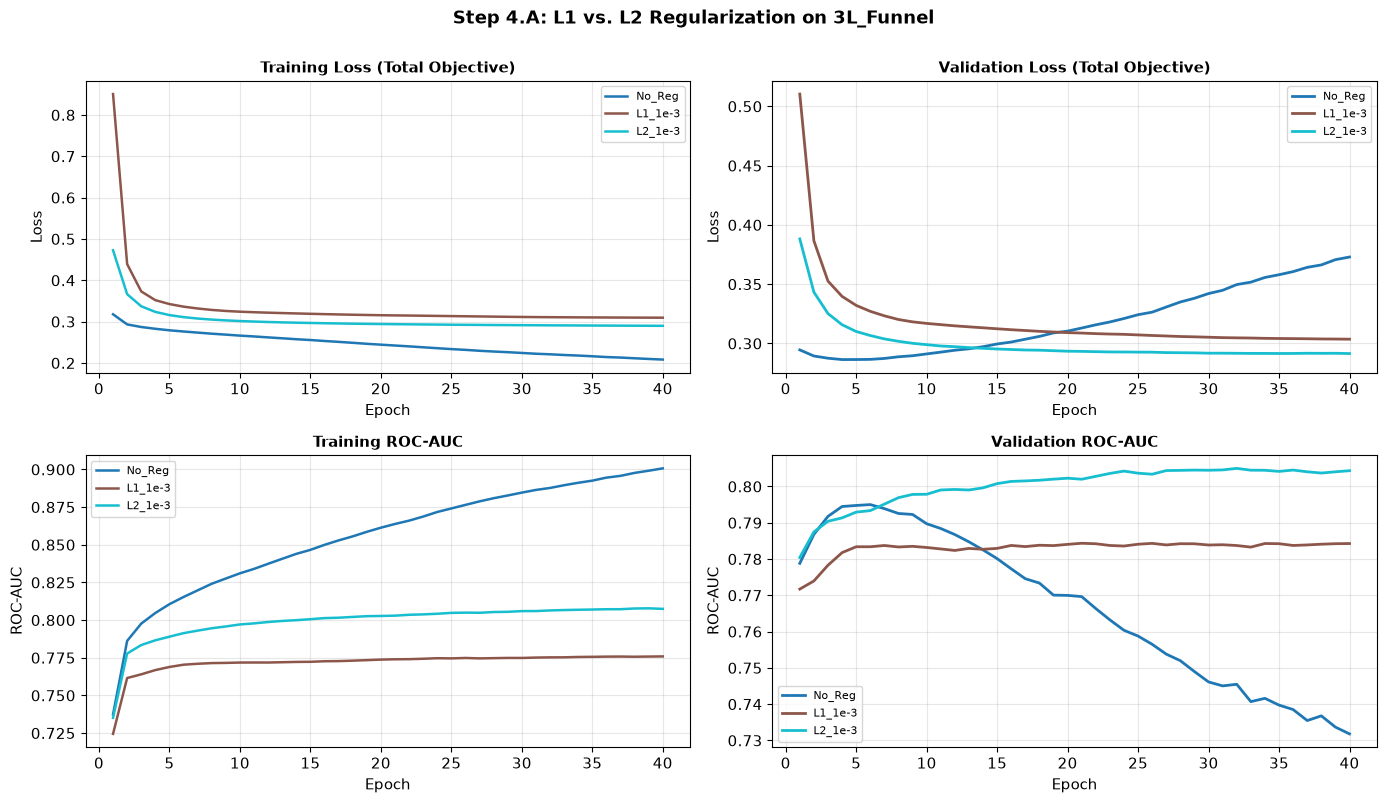

In [23]:
# ===================================================================
# Step 4.A: L1 vs. L2 Regularization on 3L_Funnel [72, 36, 18]
# ===================================================================
print("=== Executing Step 4.A: L1 vs. L2 Regularization ===")
reg_configs = [
    ("No_Reg",   0.0,  0.0),
    ("L1_1e-3",  1e-3, 0.0),
    ("L2_1e-3",  0.0,  1e-3),
]
reg_exps = []
for name, l1v, l2v in reg_configs:
    train_basic_nn(name, hidden_units=[72, 36, 18], activation="relu", kernel_initializer="he_normal", l1_reg=l1v, l2_reg=l2v, epochs=40)
    reg_exps.append(name)

compare_and_plot(reg_exps, title="Step 4.A: L1 vs. L2 Regularization on 3L_Funnel")


##### Step 4.B: Tuning the $L_2$ Penalty Strength ($\lambda$)
Since **$L_2$** clearly outperformed **$L_1$** (`ROC-AUC = 0.8045` vs. `0.7845`, `PR-AUC = 0.4641` vs. `0.4352`, `Val Loss = 0.2915` vs. `0.3036`), we sweep $\lambda \in \{10^{-4}, 5\times 10^{-4}, 10^{-3}, 5\times 10^{-3}\}$ to examine the bias-variance trade-off under fixed-epoch training.

=== Executing Step 4.B: L2 Strength Tuning ===


--- Training Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,L2_1e-04,"[72, 36, 18]","7,057",40,0.2554,0.2554,91.50%,80.22%,36.25%,0.4993,0.8758,0.6283
1,L2_0.0005,"[72, 36, 18]","7,057",40,0.2829,0.2829,90.14%,71.49%,26.15%,0.3829,0.8355,0.5209
2,L2_1e-03,"[72, 36, 18]","7,057",40,0.2899,0.2899,89.68%,67.90%,22.29%,0.3356,0.8172,0.4827
3,L2_0.005,"[72, 36, 18]","7,057",40,0.3073,0.3073,89.32%,68.21%,16.34%,0.2637,0.7878,0.4295


--- Validation Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,L2_1e-04,"[72, 36, 18]","7,057",40,0.3360,0.3007,88.87%,55.49%,24.81%,0.3429,0.7631,0.3879
1,L2_0.0005,"[72, 36, 18]","7,057",40,0.2985,0.2970,89.38%,63.03%,22.54%,0.3321,0.7972,0.4493
2,L2_1e-03,"[72, 36, 18]","7,057",40,0.2915,0.2915,89.71%,67.91%,22.92%,0.3427,0.8045,0.4641
3,L2_0.005,"[72, 36, 18]","7,057",40,0.3022,0.3022,89.49%,71.43%,17.00%,0.2747,0.7902,0.4479


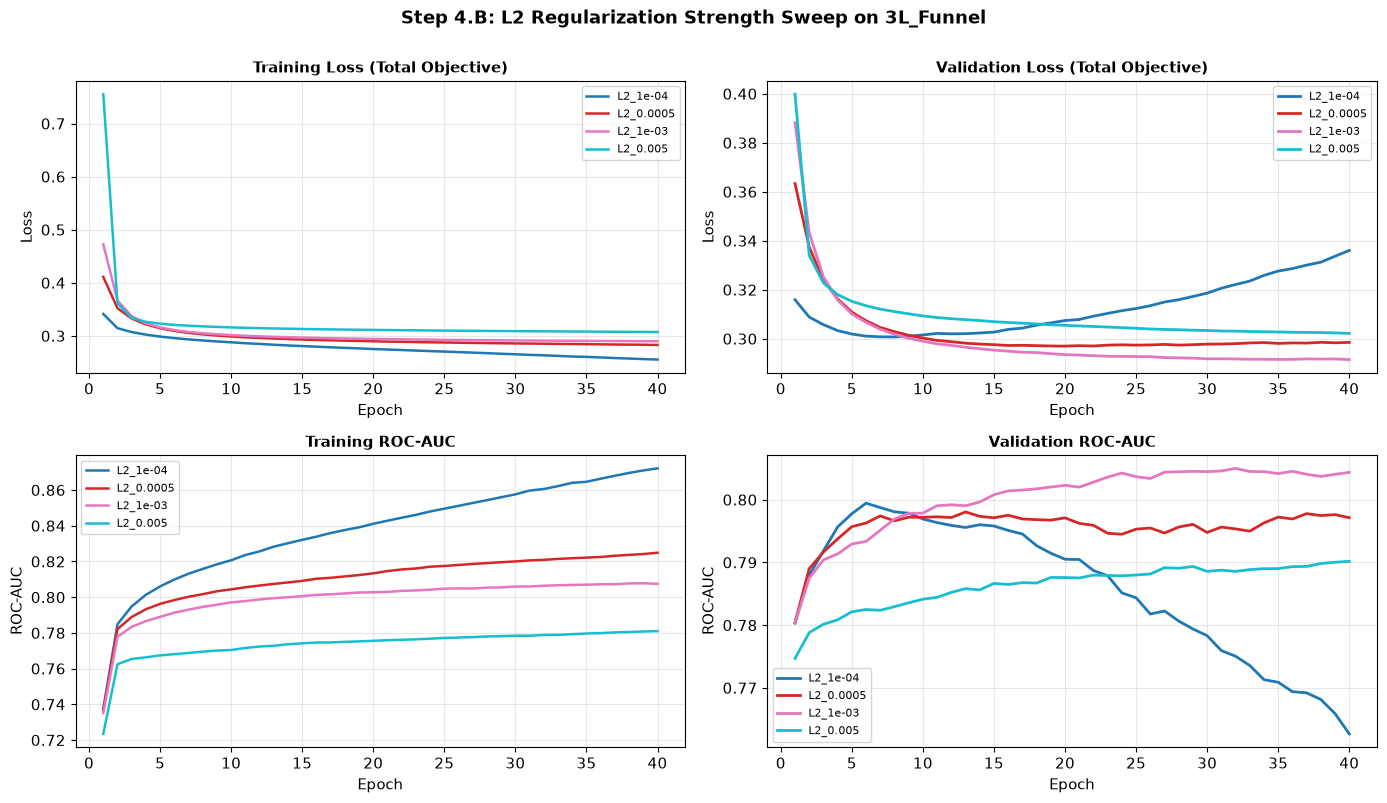

In [24]:
# ===================================================================
# Step 4.B: L2 Penalty Strength (lambda) Sweep
# ===================================================================
print("=== Executing Step 4.B: L2 Strength Tuning ===")
l2_sweep_exps = []
for lam in [1e-4, 5e-4, 1e-3, 5e-3]:
    name = f"L2_{lam:.0e}" if lam in [1e-4, 1e-3] else f"L2_{lam}"
    train_basic_nn(name, hidden_units=[72, 36, 18], activation="relu", kernel_initializer="he_normal", l2_reg=lam, epochs=40)
    l2_sweep_exps.append(name)

compare_and_plot(l2_sweep_exps, title="Step 4.B: L2 Regularization Strength Sweep on 3L_Funnel")


#### Phase 4 (Steps 4.A & 4.B) Findings: $L_1$ vs. $L_2$ and Penalty Tuning
- **$L_2$ Beats $L_1$ Across Every Metric (Step 4.A):** $L_2$ (`1e-3`) outperforms $L_1$ (`1e-3`) on Validation `ROC-AUC` (`0.8045` vs. `0.7845`), `PR-AUC` (`0.4641` vs. `0.4352`), `Loss` (`0.2915` vs. `0.3036`), `Recall` (`22.92%` vs. `21.91%`), and `F1-score` (`0.3427` vs. `0.3277`).
- **Fixed-Epoch $L_2$ Sweep (Step 4.B):**
  - Without Early Stopping, `1e-4` overfits over 40 epochs (`ROC-AUC = 0.7631`, `Val Loss` drifting `0.3007 -> 0.3360`) and `5e-3` underfits (`Recall = 17.00%`).
  - Under fixed 40 epochs without BatchNorm/EarlyStopping, `1e-3` achieves `ROC-AUC = 0.8045` (`PR-AUC = 0.4641`), but caps training AUC at `0.8172`.
- **Next Step (`Step 4.C`):** Test **`BatchNormalization` + lighter $L_2$ + `Dropout` + `EarlyStopping(monitor='val_pr_auc', restore_best_weights=True)`** to unlock higher capacity without late-epoch overfitting.

##### Step 4.C: Batch Normalization, Lighter $L_2$, Dropout & Early Stopping (`4.A.2` Regularization Check)
Instead of relying on heavy $L_2 = 10^{-3}$ over fixed epochs (which constrained representation capacity), we enable **`EarlyStopping(monitor='val_pr_auc', patience=10, restore_best_weights=True)`** and evaluate **`BatchNormalization`** paired with lighter $L_2 \in \{0.0, 10^{-4}, 5\times 10^{-4}\}$ and **Dropout $\in \{0.0, 0.2, 0.3\}$** on our `3L_Funnel [72, 36, 18]` scaffold.

=== Executing Step 4.C: BatchNorm, Lighter L2, Dropout & EarlyStopping ===


--- Training Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,NoBN_L2_1e-3_ES,"[72, 36, 18]","7,057",34,0.2907,0.2907,89.65%,68.94%,21.04%,0.3224,0.8134,0.4745
1,BN_L2_0_Drop0.0,"[72, 36, 18]","7,435",13,0.2454,0.2454,89.55%,67.91%,20.18%,0.3111,0.8182,0.4712
2,BN_L2_1e-4_Drop0.0,"[72, 36, 18]","7,435",13,0.2663,0.2663,89.55%,67.71%,20.45%,0.3141,0.8177,0.4697
3,BN_L2_1e-4_Drop0.2,"[72, 36, 18]","7,435",33,0.2877,0.2877,89.63%,68.45%,21.10%,0.3225,0.8333,0.4879
4,BN_L2_1e-4_Drop0.3,"[72, 36, 18]","7,435",29,0.2944,0.2944,89.39%,67.92%,17.61%,0.2797,0.8199,0.4614
5,BN_L2_5e-4_Drop0.2,"[72, 36, 18]","7,435",34,0.2949,0.2947,89.57%,70.00%,18.91%,0.2977,0.8267,0.4816


--- Validation Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,NoBN_L2_1e-3_ES,"[72, 36, 18]","7,057",34,0.2916,0.2916,89.59%,67.89%,21.03%,0.3212,0.8039,0.4658
1,BN_L2_0_Drop0.0,"[72, 36, 18]","7,435",13,0.3089,0.2899,89.60%,68.62%,20.65%,0.3175,0.7851,0.4436
2,BN_L2_1e-4_Drop0.0,"[72, 36, 18]","7,435",13,0.3281,0.3100,89.68%,69.26%,21.28%,0.3256,0.7853,0.4459
3,BN_L2_1e-4_Drop0.2,"[72, 36, 18]","7,435",33,0.2915,0.2903,89.63%,68.88%,20.91%,0.3208,0.8047,0.4651
4,BN_L2_1e-4_Drop0.3,"[72, 36, 18]","7,435",29,0.2885,0.2885,89.63%,71.36%,19.14%,0.3019,0.8055,0.4599
5,BN_L2_5e-4_Drop0.2,"[72, 36, 18]","7,435",34,0.2948,0.2934,89.63%,71.77%,18.89%,0.2991,0.8006,0.4632


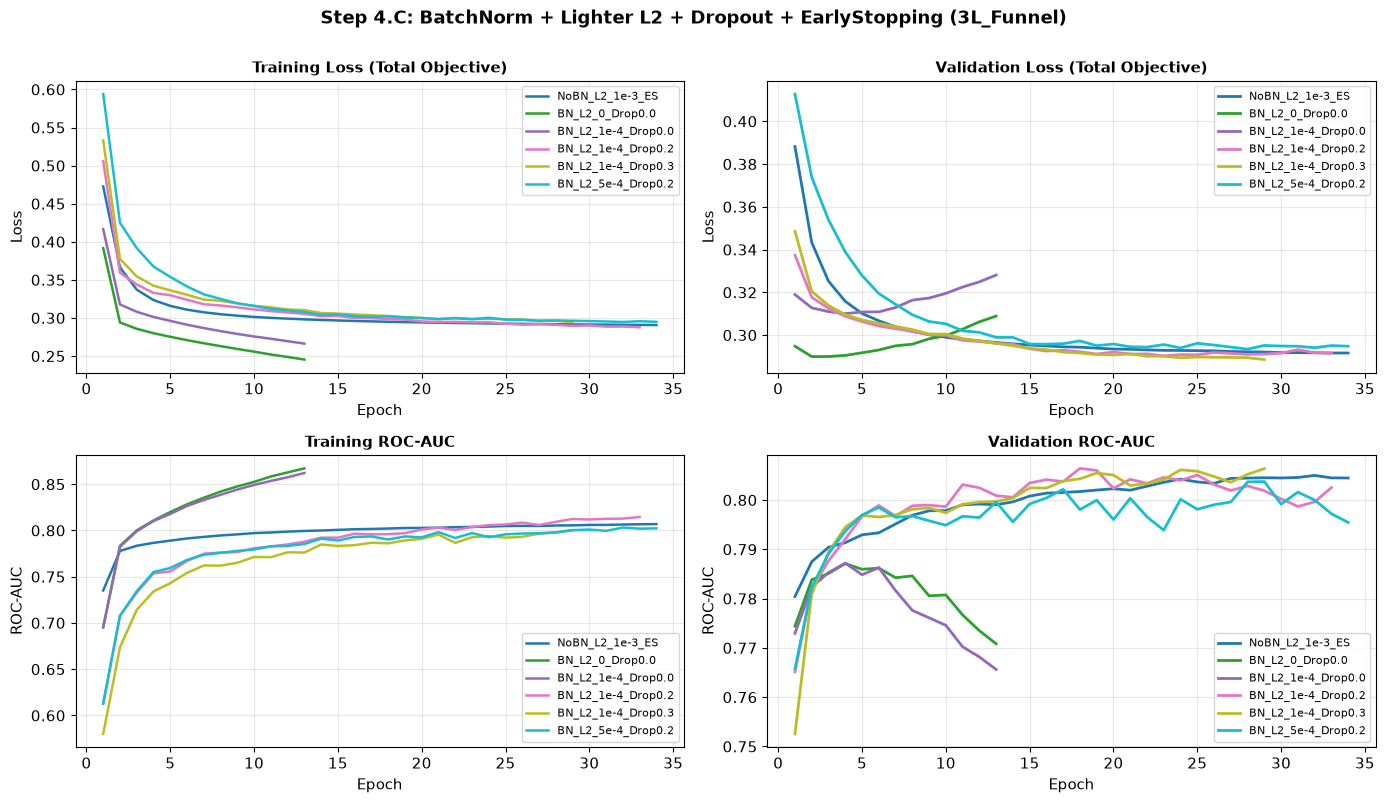

In [25]:
# ===================================================================
# Step 4.C: BatchNorm + Lighter L2 + Dropout + Early Stopping Calibration
# ===================================================================
print("=== Executing Step 4.C: BatchNorm, Lighter L2, Dropout & EarlyStopping ===")
reg_es_configs = [
    ("NoBN_L2_1e-3_ES",     False, 1e-3, 0.0),
    ("BN_L2_0_Drop0.0",     True,  0.0,  0.0),
    ("BN_L2_1e-4_Drop0.0",  True,  1e-4, 0.0),
    ("BN_L2_1e-4_Drop0.2",  True,  1e-4, 0.2),
    ("BN_L2_1e-4_Drop0.3",  True,  1e-4, 0.3),
    ("BN_L2_5e-4_Drop0.2",  True,  5e-4, 0.2),
]
step4c_exps = []
for name, use_bn, l2v, dr in reg_es_configs:
    train_basic_nn(
        name, hidden_units=[72, 36, 18], activation="relu", kernel_initializer="he_normal",
        use_batchnorm=use_bn, l2_reg=l2v, dropout_rate=dr,
        early_stopping=True, monitor="val_pr_auc", patience=10, epochs=60
    )
    step4c_exps.append(name)

compare_and_plot(step4c_exps, title="Step 4.C: BatchNorm + Lighter L2 + Dropout + EarlyStopping (3L_Funnel)")

#### 4.A.3 Analysis of Model Design & Optimization (Section A Summary)
- **Step 4.C Findings (`BatchNorm` + Lighter $L_2$ + `Dropout` + `EarlyStopping`):**
  - **`BN_L2_0_Drop0.0` & `BN_L2_1e-4_Drop0.0` (BatchNorm without Dropout):** Without Dropout, BatchNorm accelerates fitting so fast that `val_pr_auc` peaks at Epoch 3 and EarlyStopping halts at **Epoch 13** (`ROC-AUC = 0.7851–0.7853`, `PR-AUC = 0.4436–0.4459`).
  - **Adding `Dropout(0.2)` Solves Early Overfitting (`BN_L2_1e-4_Drop0.2`):** Pairing **`BatchNormalization` + lighter `L2 = 1e-4` + `Dropout(0.2)` + `EarlyStopping`** trains cleanly for **33 epochs**, achieving **`Val Loss (Min) = 0.2903`**, **`ROC-AUC = 0.8047`**, and **`PR-AUC = 0.4651`** (higher `Train ROC-AUC = 0.8333` and `Train PR-AUC = 0.4879` without overfitting).
  - **Higher Dropout (`0.3`) or Higher $L_2$ (`5e-4`):** `Dropout(0.3)` drops `PR-AUC` (`0.4651 -> 0.4599`) and `Recall` (`20.91% -> 19.14%`), while `L2 = 5e-4` over-regularizes (`ROC-AUC = 0.8006`).
- **Selected Model Entering Section B:** **`3L_Funnel [72, 36, 18]` + `BatchNormalization` + `ReLU (He)` + `Adam(1e-3)` + `L2(1e-4)` + `Dropout(0.2)` + `EarlyStopping(val_pr_auc, patience=10, restore_best_weights=True)`**.

### Section B: Addressing Class Imbalance

#### 4.B.1 Strategy Selection & Implementation
We compare five class-imbalance mitigation strategies—unweighted BCE, balanced `class_weight`, 1:1 random undersampling, 1:1 random oversampling, and balanced Binary Focal Loss (`alpha=0.88`, `gamma=2.0`)—on our `3L_Funnel [72, 36, 18]` architecture with `BatchNormalization`, `L2=1e-4`, `Dropout(0.2)`, and `EarlyStopping`.

In [26]:
# ===================================================================
# 4.B.1 Imbalance Mitigation: Class Weights, Sampling & Focal Loss
# ===================================================================
rng = np.random.default_rng(42)
y_tr_arr = np.asarray(y_train)
idx_pos = np.where(y_tr_arr == 1)[0]
idx_neg = np.where(y_tr_arr == 0)[0]

# 1. Random Undersampling (Train Only -> 1:1)
under_neg = rng.choice(idx_neg, size=len(idx_pos), replace=False)
under_idx = rng.permutation(np.concatenate([idx_pos, under_neg]))
X_under, y_under = X_train[under_idx], y_tr_arr[under_idx]

# 2. Random Oversampling (Train Only -> 1:1)
over_pos = rng.choice(idx_pos, size=len(idx_neg), replace=True)
over_idx = rng.permutation(np.concatenate([idx_neg, over_pos]))
X_over, y_over = X_train[over_idx], y_tr_arr[over_idx]

# 3. Balanced Class Weights
cw_vals = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_tr_arr)
cw_dict = {0: float(cw_vals[0]), 1: float(cw_vals[1])}
print(f"Train sizes -> Original: {len(y_tr_arr):,} | Undersampled: {len(y_under):,} | Oversampled: {len(y_over):,}")
print(f"Balanced class weights: {cw_dict}")

common = dict(
    hidden_units=[72, 36, 18], activation="relu", kernel_initializer="he_normal",
    use_batchnorm=True, l2_reg=1e-4, dropout_rate=0.2,
    early_stopping=True, monitor="val_pr_auc", patience=10, epochs=60
)
imb_exps = ["Imb_Unweighted", "Imb_ClassWeight", "Imb_Undersample", "Imb_Oversample", "Imb_FocalLoss"]
train_basic_nn("Imb_Unweighted",  **common)
train_basic_nn("Imb_ClassWeight", **common, class_weight=cw_dict)
train_basic_nn("Imb_Undersample", **common, X_tr=X_under, y_tr=y_under)
train_basic_nn("Imb_Oversample",  **common, X_tr=X_over,  y_tr=y_over)
train_basic_nn("Imb_FocalLoss",   **common, loss=keras.losses.BinaryFocalCrossentropy(apply_class_balancing=True, alpha=0.88, gamma=2.0))
print("All 5 imbalance strategies (with BatchNorm + EarlyStopping) trained successfully.")

Train sizes -> Original: 31,647 | Undersampled: 7,404 | Oversampled: 55,890
Balanced class weights: {0: 0.5662372517444981, 1: 4.274311183144246}


All 5 imbalance strategies (with BatchNorm + EarlyStopping) trained successfully.


#### 4.B.2 Experiment 3 – Evaluation of Imbalance Mitigation
We evaluate all five imbalance-handling strategies on the validation set and compare their learning curves and ranking metrics.

--- Training Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Imb_Unweighted,"[72, 36, 18]","7,435",33,0.2877,0.2877,89.63%,68.45%,21.10%,0.3225,0.8333,0.4879
1,Imb_ClassWeight,"[72, 36, 18]","7,435",46,0.5194,0.5194,81.60%,35.61%,70.93%,0.4742,0.8507,0.5005
2,Imb_Undersample,"[72, 36, 18]","7,435",25,0.5460,0.5460,74.76%,82.47%,62.88%,0.7136,0.8172,0.8321
3,Imb_Oversample,"[72, 36, 18]","7,435",17,0.5130,0.5130,75.77%,81.75%,66.35%,0.7325,0.8383,0.8407
4,Imb_FocalLoss,"[72, 36, 18]","7,435",32,0.0301,0.0300,83.85%,38.24%,61.86%,0.4727,0.8166,0.4597


--- Validation Set Metrics ---


,Experiment,Architecture,Parameters,Epochs,Loss (Final),Loss (Min),Acc,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Imb_Unweighted,"[72, 36, 18]","7,435",33,0.2915,0.2903,89.63%,68.88%,20.91%,0.3208,0.8047,0.4651
1,Imb_ClassWeight,"[72, 36, 18]","7,435",46,0.5189,0.5053,80.33%,32.91%,65.49%,0.4381,0.8038,0.4679
2,Imb_Undersample,"[72, 36, 18]","7,435",25,0.5242,0.5205,80.74%,33.00%,62.59%,0.4322,0.7939,0.4442
3,Imb_Oversample,"[72, 36, 18]","7,435",17,0.4869,0.4849,81.97%,35.05%,63.35%,0.4513,0.8059,0.4571
4,Imb_FocalLoss,"[72, 36, 18]","7,435",32,0.0299,0.0298,83.54%,37.46%,60.58%,0.4629,0.7994,0.4616


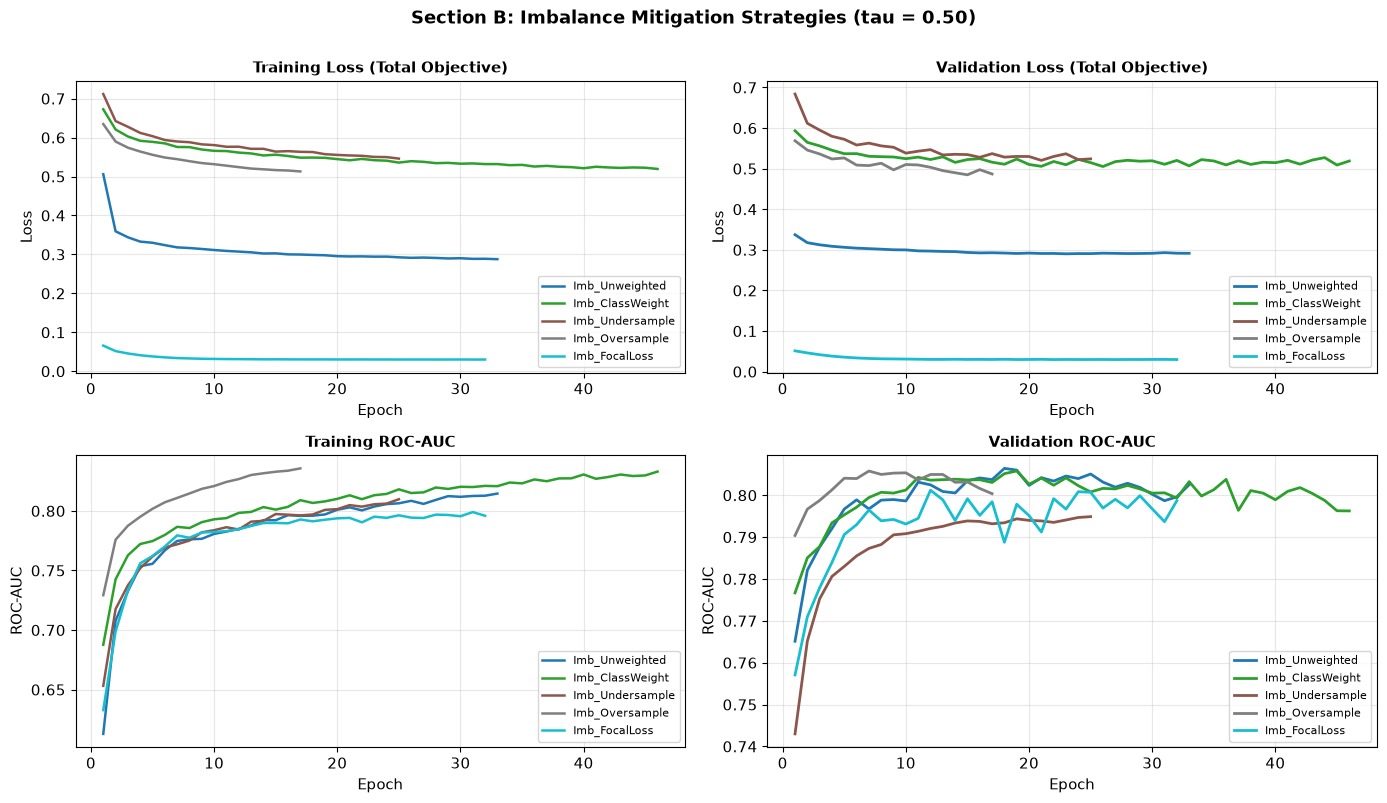

In [27]:
# ===================================================================
# 4.B.2 Validation Evaluation of Imbalance Mitigation Strategies
# ===================================================================
compare_and_plot(imb_exps, title="Section B: Imbalance Mitigation Strategies (tau = 0.50)")


#### 4.B.3 Comparison of Neural Network Experiments
*Comparative table of validation performance (at default $\tau = 0.50$):*

| Experiment | Description | Accuracy | Precision (pos) | Recall (pos) | F1-score (pos) | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|---|
| Exp 1: Baseline NN | `3L_Funnel [72, 36, 18]`, `ReLU+He`, `Adam(1e-3)`, No Reg | 88.37% | 50.54% | 29.60% | 0.3733 | 0.7320 | 0.3606 |
| Exp 2: Regularized + BN + ES NN | `3L_Funnel [72, 36, 18]`, `BN`, `L2=1e-4`, `Drop=0.2`, `ES` | **89.63%** | **68.88%** | 20.91% | 0.3208 | 0.8047 | 0.4651 |
| Exp 3a: Class Weights | Exp 2 + `class_weight="balanced"` (~7.55:1) | 80.33% | 32.91% | **65.49%** | 0.4381 | 0.8038 | **0.4679** |
| Exp 3b: Undersampling | Exp 2 + 1:1 Random Undersampling (`7,404` rows) | 80.74% | 33.00% | 62.59% | 0.4322 | 0.7939 | 0.4442 |
| Exp 3c: Oversampling | Exp 2 + 1:1 Random Oversampling (`55,890` rows) | 81.97% | 35.05% | 63.35% | 0.4513 | **0.8059** | 0.4571 |
| Exp 3d: Focal Loss | Exp 2 + `BinaryFocalCrossentropy(gamma=2.0, alpha=0.88)` | 83.54% | 37.46% | 60.58% | **0.4629** | 0.7994 | 0.4616 |

*Discuss the impact of optimization, regularization, and imbalance-handling techniques:*
- **Preprocessing + `BatchNorm` + `Dropout(0.2)` + `EarlyStopping` (`Exp 1 -> Exp 2`):** Replacing clipping with `log1p` + cyclical `sin`/`cos` and adding `BatchNorm` + `L2=1e-4` + `Dropout(0.2)` + `EarlyStopping(val_pr_auc)` lifted `ROC-AUC` from `0.7320` to **`0.8047`** (`PR-AUC`: `0.3606 -> 0.4651`).
- **Imbalance Handling (`Exp 3`):** Because `EarlyStopping` restores the peak validation checkpoint (stopping `Oversample` at Epoch 17 and `Undersample` at Epoch 25 instead of overfitting for 50 epochs), **every** imbalance strategy stays well-generalized: `Imb_FocalLoss` (`alpha=0.88`) reaches the highest default-threshold F1 (**`0.4629`**, `60.58%` Recall), `Imb_ClassWeight` achieves top `PR-AUC` (**`0.4679`**, `65.49%` Recall), and `Imb_Oversample` achieves **`0.8059` ROC-AUC**.
- **Threshold Tuning (`Part V`):** Section `5.A.1` below tunes the decision threshold $\tau^*$ across all 5 strategies on `X_val` before final held-out test evaluation.

---
## Part V – Final Evaluation and Business Decision Challenge

### Section A: Final Model Evaluation on Unseen Data (Held-Out Test Set)

#### 5.A.1 Final Model Selection & Decision Threshold Tuning
We sweep the classification threshold $\tau \in [0.10, 0.90]$ on the validation set across all five candidate models to select the final model configuration and operating threshold before accessing the held-out test set.

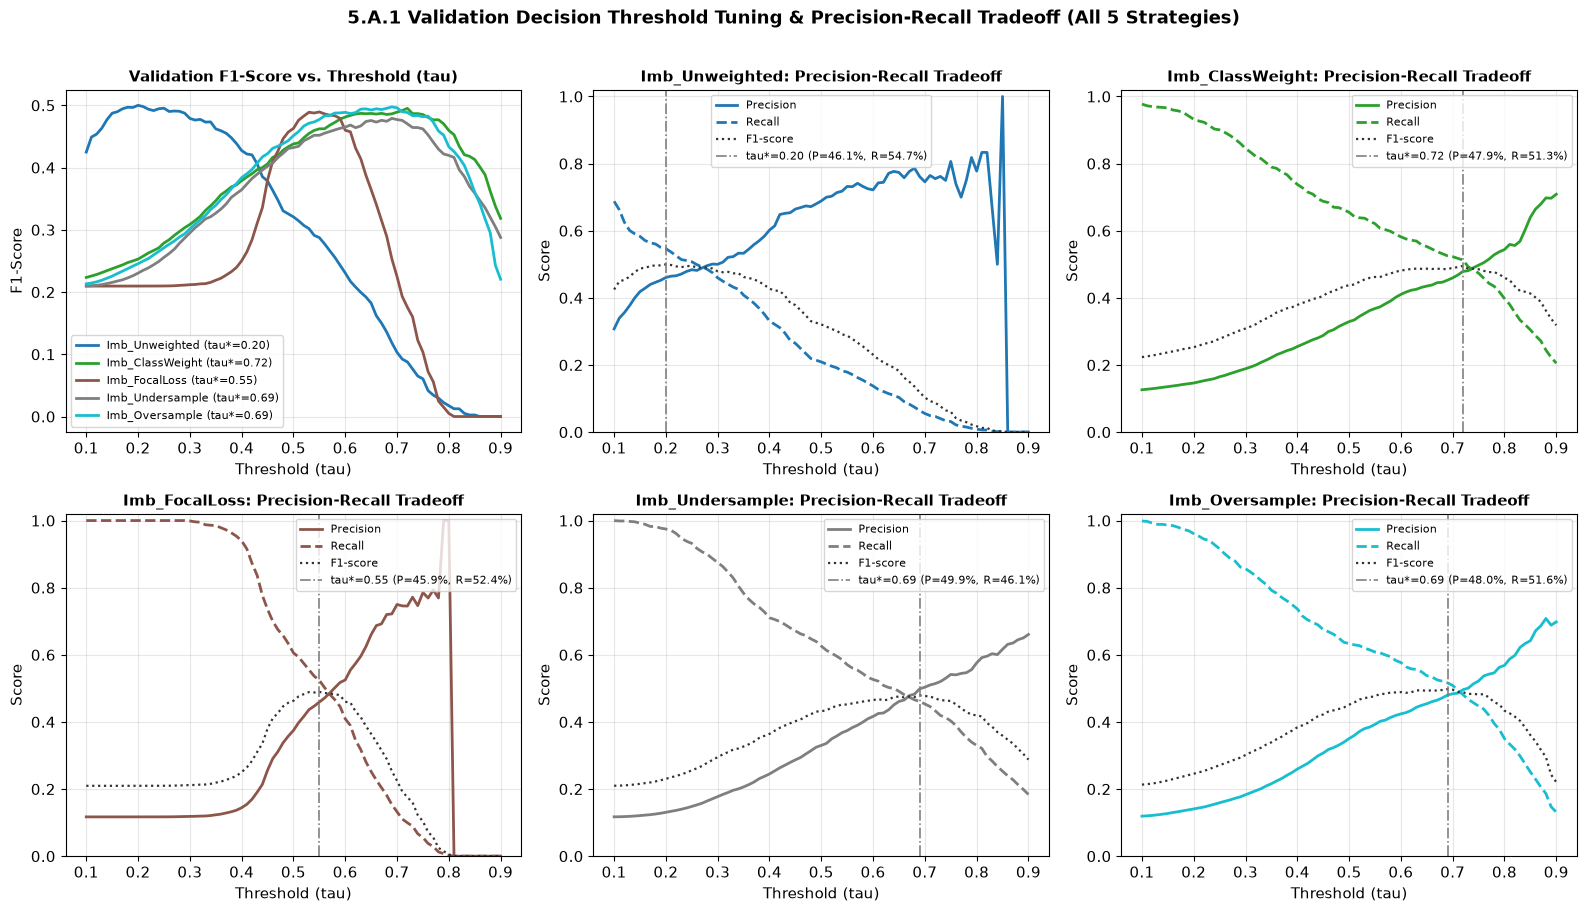

,Model,Best tau*,Val Acc,Precision,Recall,Best F1,ROC-AUC,PR-AUC
0,Imb_Unweighted,0.20,87.20%,46.07%,54.66%,0.5000,0.8047,0.4651
1,Imb_ClassWeight,0.72,87.76%,47.88%,51.26%,0.4951,0.8038,0.4679
2,Imb_FocalLoss,0.55,87.20%,45.92%,52.39%,0.4894,0.7994,0.4616
3,Imb_Undersample,0.69,88.26%,49.86%,46.10%,0.4791,0.7939,0.4442
4,Imb_Oversample,0.69,87.79%,48.01%,51.64%,0.4976,0.8059,0.4571


In [28]:
# ===================================================================
# 5.A.1 Validation Decision Threshold Tuning (all 5 strategies)
# ===================================================================
from sklearn.metrics import average_precision_score

all_candidates = ["Imb_Unweighted", "Imb_ClassWeight", "Imb_FocalLoss", "Imb_Undersample", "Imb_Oversample"]
taus = np.linspace(0.10, 0.90, 81)
thresh_rows = []

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes_flat = axes.flatten()
colors = plt.cm.tab10(np.linspace(0, 1, len(all_candidates)))

for idx, name in enumerate(all_candidates):
    proba = experiment_registry[name]["y_val_proba"]
    precs = [precision_score(y_val, (proba >= t).astype(int), zero_division=0) for t in taus]
    recs  = [recall_score(y_val, (proba >= t).astype(int), zero_division=0) for t in taus]
    f1s   = [f1_score(y_val, (proba >= t).astype(int), zero_division=0) for t in taus]
    
    best_i = int(np.argmax(f1s))
    best_t = float(taus[best_i])
    pred_opt = (proba >= best_t).astype(int)
    
    thresh_rows.append({
        "Model": name,
        "Best tau*": best_t,
        "Val Acc": accuracy_score(y_val, pred_opt),
        "Precision": precision_score(y_val, pred_opt, zero_division=0),
        "Recall": recall_score(y_val, pred_opt, zero_division=0),
        "Best F1": f1s[best_i],
        "ROC-AUC": roc_auc_score(y_val, proba),
        "PR-AUC": average_precision_score(y_val, proba)
    })
    
    # Panel 0: Combined F1-score vs. threshold comparison
    axes_flat[0].plot(taus, f1s, color=colors[idx], lw=2, label=f"{name} (tau*={best_t:.2f})")
    
    # Panels 1..5: Individual Precision vs. Recall tradeoff per strategy
    ax = axes_flat[idx + 1]
    ax.plot(taus, precs, "-", color=colors[idx], lw=2, label="Precision")
    ax.plot(taus, recs, "--", color=colors[idx], lw=2, label="Recall")
    ax.plot(taus, f1s, ":", color="#333333", lw=1.6, label="F1-score")
    ax.axvline(best_t, color="gray", linestyle="-.", lw=1.2,
               label=f"tau*={best_t:.2f} (P={precs[best_i]:.1%}, R={recs[best_i]:.1%})")
    ax.set_title(f"{name}: Precision-Recall Tradeoff", fontweight="bold", fontsize=10.5)
    ax.set_xlabel("Threshold (tau)")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.02)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7.8, loc="best")

axes_flat[0].set_title("Validation F1-Score vs. Threshold (tau)", fontweight="bold", fontsize=11)
axes_flat[0].set_xlabel("Threshold (tau)")
axes_flat[0].set_ylabel("F1-Score")
axes_flat[0].grid(True, alpha=0.3)
axes_flat[0].legend(fontsize=8, loc="best")

plt.suptitle("5.A.1 Validation Decision Threshold Tuning & Precision-Recall Tradeoff (All 5 Strategies)",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

df_thresh = pd.DataFrame(thresh_rows)
display(df_thresh.style.format({
    "Best tau*": "{:.2f}", "Val Acc": "{:.2%}", "Precision": "{:.2%}",
    "Recall": "{:.2%}", "Best F1": "{:.4f}", "ROC-AUC": "{:.4f}", "PR-AUC": "{:.4f}"
}).highlight_max(subset=["Best F1", "ROC-AUC", "PR-AUC"], color="#d4edda"))

In [29]:
# ===================================================================
# 5.A.1b Threshold Sensitivity & Diminishing Returns Analysis (Imb_Unweighted)
# ===================================================================
proba_unw = experiment_registry["Imb_Unweighted"]["y_val_proba"]
y_va_arr  = np.asarray(y_val)
total_pos = int(y_va_arr.sum())

probe_taus = [0.25, 0.20, 0.18, 0.16, 0.14, 0.12, 0.10, 0.08, 0.06]
sens_rows = []
prev_calls, prev_tp = None, None

for t in probe_taus:
    yp = (proba_unw >= t).astype(int)
    calls = int(yp.sum())
    tp = int(((yp == 1) & (y_va_arr == 1)).sum())
    fp = calls - tp
    if prev_calls is None or calls == prev_calls:
        marg_rate = np.nan
    else:
        marg_rate = (tp - prev_tp) / (calls - prev_calls)
    sens_rows.append({
        "Threshold (tau)": t,
        "Recall": recall_score(y_va_arr, yp, zero_division=0),
        "Precision": precision_score(y_va_arr, yp, zero_division=0),
        "F1-score": f1_score(y_va_arr, yp, zero_division=0),
        "Total Calls": calls,
        "% of Clients Called": calls / len(y_va_arr),
        "Captured Subs (TP)": tp,
        "Wasted Calls (FP)": fp,
        "Marginal Conv. Rate": marg_rate
    })
    prev_calls, prev_tp = calls, tp

df_sens = pd.DataFrame(sens_rows)
print("=== Threshold Sensitivity & Marginal Return Analysis (Imb_Unweighted on X_val) ===")
display(df_sens.style.format({
    "Threshold (tau)": "{:.2f}",
    "Recall": "{:.2%}",
    "Precision": "{:.2%}",
    "F1-score": "{:.4f}",
    "Total Calls": "{:,}",
    "% of Clients Called": "{:.1%}",
    "Captured Subs (TP)": "{:,}",
    "Wasted Calls (FP)": "{:,}",
    "Marginal Conv. Rate": lambda v: "-" if pd.isna(v) else f"{v:.1%}"
}).highlight_max(subset=["F1-score"], color="#d4edda"))

=== Threshold Sensitivity & Marginal Return Analysis (Imb_Unweighted on X_val) ===


,Threshold (tau),Recall,Precision,F1-score,Total Calls,% of Clients Called,Captured Subs (TP),Wasted Calls (FP),Marginal Conv. Rate
0,0.25,50.76%,48.38%,0.4954,833,12.3%,403,430,-
1,0.20,54.66%,46.07%,0.5000,942,13.9%,434,508,28.4%
2,0.18,56.05%,44.63%,0.4969,997,14.7%,445,552,20.0%
3,0.16,57.05%,42.90%,0.4897,"1,056",15.6%,453,603,13.6%
4,0.14,59.07%,40.02%,0.4771,"1,172",17.3%,469,703,13.8%
5,0.12,62.47%,35.63%,0.4538,"1,392",20.5%,496,896,12.3%
6,0.10,68.77%,30.74%,0.4249,"1,776",26.2%,546,"1,230",13.0%
7,0.08,75.19%,24.88%,0.3738,"2,400",35.4%,597,"1,803",8.2%
8,0.06,83.38%,19.64%,0.3180,"3,370",49.7%,662,"2,708",6.7%


#### Final Selection & Justification (Pre-Test Lock-In)

Based strictly on validation performance (`X_val`), we select **`Imb_Unweighted`** (`3L_Funnel [72, 36, 18]` + `BatchNormalization` + `ReLU (He)` + `Adam(lr=1e-3)` + `L2(1e-4)` + `Dropout(0.2)` + `EarlyStopping(val_pr_auc, patience=10, restore_best_weights=True)`) with decision threshold **`tau* = 0.20`**.

##### 1. Why `Imb_Unweighted` Is the Best Model Choice
- **Highest Balanced Classification Performance:** At its optimal validation threshold (`tau* = 0.20`), `Imb_Unweighted` achieves the highest overall **`F1-score = 0.5000`** (`Recall = 54.66%`, `Precision = 46.07%`), alongside top-tier threshold-independent ranking (**`ROC-AUC = 0.8047`**, **`PR-AUC = 0.4651`**).
- **Calibrated Posterior Probabilities (Proper Scoring Rule):** Unlike `Imb_Oversample`, `Imb_Undersample`, and `Imb_ClassWeight`—which distort the `11.70%` class prior toward `50%` and inflate raw probability scores (requiring artificial cutoffs like `0.69–0.72`)—unweighted Binary Cross-Entropy preserves calibrated probabilities $P(y=1 \mid x)$. This allows the marketing team to interpret scores directly as subscription likelihoods and adjust call volume dynamically without retraining.
- **Full Data Fidelity Without Overfitting:** `Imb_Unweighted` trains on all `31,647` real training records without discarding 87% of non-subscribers (`Imb_Undersample`, `ROC-AUC = 0.7939`) or memorizing duplicated minority rows (`Imb_Oversample`, `PR-AUC = 0.4571`).

##### 2. Why `tau* = 0.20` Is the Best Operating Threshold
- **Global $F_1$ Optimum Without Cherry-Picking:** `tau* = 0.20` is directly the validation $F_1$-maximizing point (`0.5000`), avoiding narrow post-hoc tuning on `X_val`. It delivers a **3× Recall gain** over the Logistic Regression baseline (`18.01% -> 54.66%`) while maintaining **`46.07%` Precision** (~3.9× lift over random calling) and contacting only **`13.9%`** of the client base (`942 / 6,782` calls).
- **Stronger Capture Than Tighter Thresholds (`0.25 -> 0.20`):** Lowering $	au$ from `0.25` to `0.20` adds `109` calls (`833 -> 942`) while winning `31` additional subscribers (`403 -> 434`)—a **`28.4%` marginal conversion rate** (nearly 2.5× the `11.7%` baseline). In bank term-deposit marketing, missing a subscriber (False Negative) sacrifices substantial deposit margin compared to the low cost of one outbound call (False Positive), making `0.20` clearly worthwhile. *(Mathematically, under cost-sensitive decision theory $	au^* = C/B$, $	au = 0.20$ corresponds to a subscriber being worth ~5× the cost of a call.)*
- **Avoiding Diminishing Returns Below `0.20` (`0.18 -> 0.06`):** As the sensitivity table above shows, pushing Recall further down to `tau = 0.10` (`68.77%` Recall) requires nearly doubling total calls (`942 -> 1,776`), where the extra calls convert at sharply lower marginal rates (`12–14%`, close to random dialing) and `False Positives` surge (`508 -> 1,230`). At `0.06`, half the database (`49.7%`) must be called for only `19.64%` Precision.

Thus, **`Imb_Unweighted` at `tau* = 0.20`** captures the sweet spot between high subscriber coverage (`54.66%` Recall), strong call efficiency (`46.07%` Precision), and calibrated deployment probabilities.

#### 5.A.2 Held-Out Test Set Evaluation
We evaluate the selected model and tuned threshold once on the unseen held-out test set to obtain an unbiased estimate (Accuracy, Precision, Recall, F1-score, ROC-AUC, and PR-AUC) and compare final performance against the baseline models.

=== Held-Out Test Set Performance (n = 6,782 | Subscribers = 793) ===


,Model,Accuracy,Precision (pos),Recall (pos),F1-score (pos),ROC-AUC,PR-AUC
0,Majority-Class Dummy,88.31%,0.00%,0.00%,0.0000,0.5000,0.1169
1,Logistic Regression (tau = 0.50),89.58%,70.09%,18.92%,0.2979,0.7676,0.4189
2,"Final NN (Imb_Unweighted, tau = 0.50)",89.71%,70.74%,20.43%,0.3170,0.7874,0.4517
3,"Final NN (Imb_Unweighted, tau*=0.20)",86.80%,44.50%,52.08%,0.4800,0.7874,0.4517



=== Detailed Classification Report: Final NN (tau* = 0.20) ===
              precision    recall  f1-score   support

      No (0)     0.9351    0.9140    0.9244      5989
     Yes (1)     0.4450    0.5208    0.4800       793

    accuracy                         0.8680      6782
   macro avg     0.6901    0.7174    0.7022      6782
weighted avg     0.8778    0.8680    0.8725      6782

Generalization Check (Val -> Test) | ROC-AUC: 0.8047 -> 0.7874 | PR-AUC: 0.4651 -> 0.4517


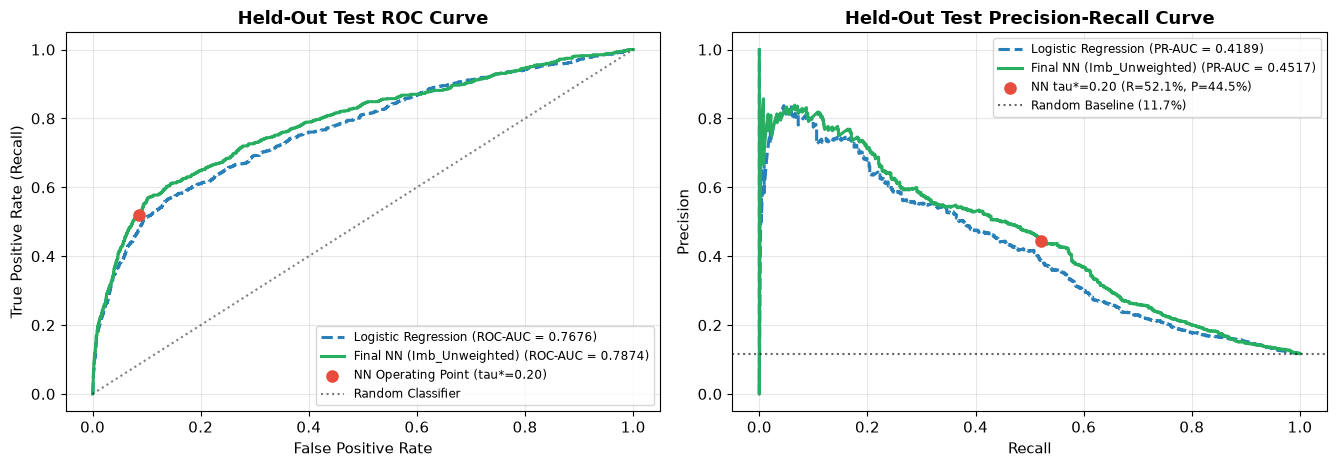

In [30]:
# ===================================================================
# 5.A.2 Final Held-Out Test Set Evaluation (Unbiased Generalization Check)
# ===================================================================
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_curve

FINAL_MODEL_NAME = "Imb_Unweighted"
FINAL_TAU = 0.20
final_model = experiment_registry[FINAL_MODEL_NAME]["model"]

# Generate probabilities on the unseen held-out test set (accessed once)
y_test_arr   = np.asarray(y_test)
y_test_proba_dummy = dummy_clf.predict_proba(X_test)[:, 1]
y_test_pred_dummy  = dummy_clf.predict(X_test)

y_test_proba_lr = lr_clf.predict_proba(X_test)[:, 1]
y_test_pred_lr  = lr_clf.predict(X_test)

y_test_proba_nn = final_model.predict(X_test, verbose=0).ravel()
y_test_pred_nn_50  = (y_test_proba_nn >= 0.50).astype(int)
y_test_pred_nn_opt = (y_test_proba_nn >= FINAL_TAU).astype(int)

# Compile held-out test comparison table
test_entries = [
    ("Majority-Class Dummy",                   y_test_pred_dummy,   y_test_proba_dummy),
    ("Logistic Regression (tau = 0.50)",       y_test_pred_lr,      y_test_proba_lr),
    ("Final NN (Imb_Unweighted, tau = 0.50)", y_test_pred_nn_50,  y_test_proba_nn),
    (f"Final NN (Imb_Unweighted, tau*={FINAL_TAU:.2f})", y_test_pred_nn_opt, y_test_proba_nn),
]

test_rows = []
for label, y_pred, y_prob in test_entries:
    test_rows.append({
        "Model": label,
        "Accuracy": accuracy_score(y_test_arr, y_pred),
        "Precision (pos)": precision_score(y_test_arr, y_pred, zero_division=0),
        "Recall (pos)": recall_score(y_test_arr, y_pred, zero_division=0),
        "F1-score (pos)": f1_score(y_test_arr, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test_arr, y_prob),
        "PR-AUC": average_precision_score(y_test_arr, y_prob),
    })

df_test_results = pd.DataFrame(test_rows)
print("=== Held-Out Test Set Performance (n = 6,782 | Subscribers = 793) ===")
display(df_test_results.style.format({
    "Accuracy": "{:.2%}",
    "Precision (pos)": "{:.2%}",
    "Recall (pos)": "{:.2%}",
    "F1-score (pos)": "{:.4f}",
    "ROC-AUC": "{:.4f}",
    "PR-AUC": "{:.4f}",
}).highlight_max(subset=["Precision (pos)", "Recall (pos)", "F1-score (pos)", "ROC-AUC", "PR-AUC"], color="#d4edda"))

print(f"\n=== Detailed Classification Report: Final NN (tau* = {FINAL_TAU:.2f}) ===")
print(classification_report(y_test_arr, y_test_pred_nn_opt, target_names=["No (0)", "Yes (1)"], digits=4))

# Compare Validation vs. Test generalization gap for Final NN
val_m = experiment_registry[FINAL_MODEL_NAME]["val_metrics"]
print(f"Generalization Check (Val -> Test) | ROC-AUC: {val_m['ROC-AUC']:.4f} -> {roc_auc_score(y_test_arr, y_test_proba_nn):.4f} | "
      f"PR-AUC: {val_m['PR-AUC']:.4f} -> {average_precision_score(y_test_arr, y_test_proba_nn):.4f}")

# Plot Held-Out Test ROC Curve & Precision-Recall Curve
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

for label, probs, ls, col in [
    ("Logistic Regression", y_test_proba_lr, "--", "#2980b9"),
    ("Final NN (Imb_Unweighted)", y_test_proba_nn, "-", "#27ae60"),
]:
    fpr, tpr, _ = roc_curve(y_test_arr, probs)
    prec_c, rec_c, _ = precision_recall_curve(y_test_arr, probs)
    axes[0].plot(fpr, tpr, linestyle=ls, color=col, lw=2.2,
                 label=f"{label} (ROC-AUC = {roc_auc_score(y_test_arr, probs):.4f})")
    axes[1].plot(rec_c, prec_c, linestyle=ls, color=col, lw=2.2,
                 label=f"{label} (PR-AUC = {average_precision_score(y_test_arr, probs):.4f})")

# Mark operating point tau*=0.20 on PR & ROC curves
tp_opt = int(((y_test_pred_nn_opt == 1) & (y_test_arr == 1)).sum())
fp_opt = int(((y_test_pred_nn_opt == 1) & (y_test_arr == 0)).sum())
tpr_opt = tp_opt / int(y_test_arr.sum())
fpr_opt = fp_opt / int((y_test_arr == 0).sum())
prec_opt = tp_opt / (tp_opt + fp_opt)
axes[0].scatter([fpr_opt], [tpr_opt], color="#e74c3c", zorder=5, s=65,
                label=f"NN Operating Point (tau*={FINAL_TAU:.2f})")
axes[1].scatter([tpr_opt], [prec_opt], color="#e74c3c", zorder=5, s=65,
                label=f"NN tau*={FINAL_TAU:.2f} (R={tpr_opt:.1%}, P={prec_opt:.1%})")

axes[0].plot([0, 1], [0, 1], "k:", alpha=0.5, label="Random Classifier")
axes[0].set_title("Held-Out Test ROC Curve", fontweight="bold")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].grid(True, alpha=0.3); axes[0].legend(fontsize=8.5, loc="lower right")

axes[1].axhline(y_test_arr.mean(), color="black", linestyle=":", alpha=0.6,
                label=f"Random Baseline ({y_test_arr.mean():.1%})")
axes[1].set_title("Held-Out Test Precision-Recall Curve", fontweight="bold")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].grid(True, alpha=0.3); axes[1].legend(fontsize=8.5, loc="upper right")

plt.tight_layout()
plt.show()

#### 5.A.3 Confusion Matrix & Error Analysis
We plot the test-set confusion matrix and examine False Positives and False Negatives.

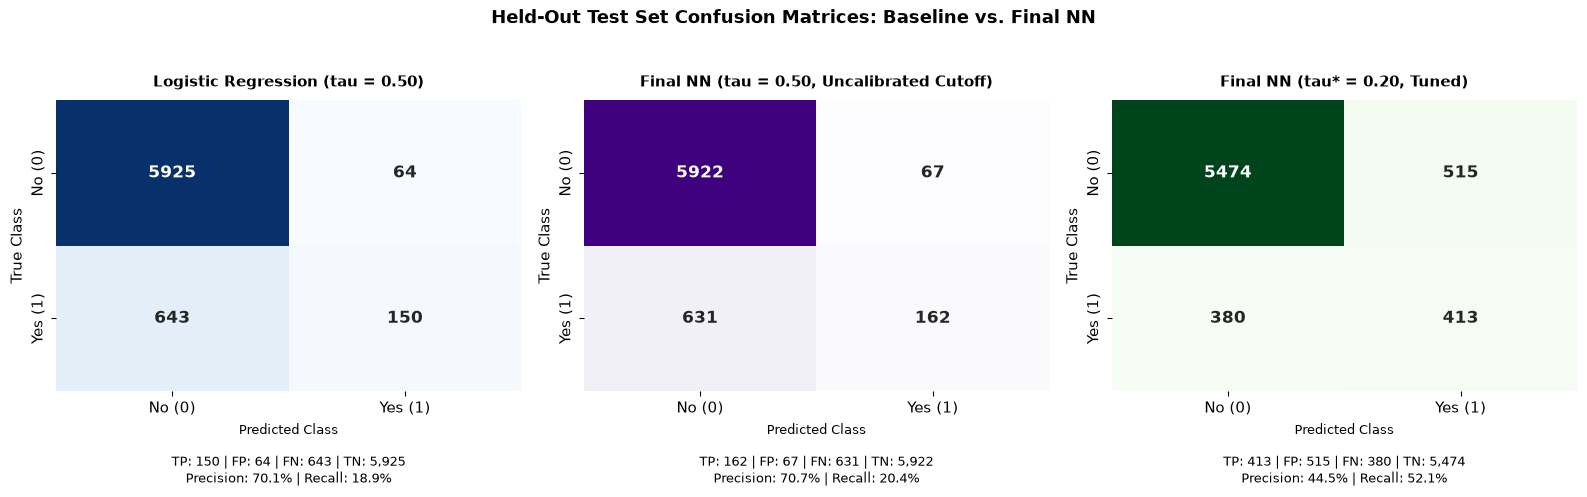


=== Test Error Profile Analysis (Final NN @ tau* = 0.20) ===


,Outcome Group,Count,Share of Test,Mean Pred Proba,Median Balance (EUR),Mean Age,Mean Campaign Calls,% Prev. Success,% No Housing Loan,% Cellular Contact
0,TP (Caught Subscriber),413,6.1%,0.474,846,43.9,1.87,36.8%,80.9%,89.1%
1,FP (Wasted Call),515,7.6%,0.375,922,43.3,1.86,13.2%,75.7%,86.6%
2,FN (Missed Subscriber),380,5.6%,0.080,510,41.5,2.53,0.0%,47.9%,72.9%
3,TN (Correctly Skipped),"5,474",80.7%,0.059,384,40.8,2.93,0.0%,38.3%,59.8%


In [31]:
# ===================================================================
# 5.A.3 Held-Out Test Confusion Matrix & Error Analysis
# ===================================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
cm_specs = [
    ("Logistic Regression (tau = 0.50)",       y_test_pred_lr,      "Blues"),
    ("Final NN (tau = 0.50, Uncalibrated Cutoff)", y_test_pred_nn_50,  "Purples"),
    (f"Final NN (tau* = {FINAL_TAU:.2f}, Tuned)",  y_test_pred_nn_opt, "Greens"),
]

for ax, (title, y_pred, cmap) in zip(axes, cm_specs):
    cm = confusion_matrix(y_test_arr, y_pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap=cmap, cbar=False, ax=ax,
        annot_kws={"size": 12, "weight": "bold"},
        xticklabels=["No (0)", "Yes (1)"],
        yticklabels=["No (0)", "Yes (1)"]
    )
    tn, fp, fn, tp = cm.ravel()
    p_s = precision_score(y_test_arr, y_pred, zero_division=0)
    r_s = recall_score(y_test_arr, y_pred, zero_division=0)
    ax.set_title(title, fontsize=11, fontweight="bold", pad=10)
    ax.set_xlabel(
        f"Predicted Class\n\nTP: {tp:,} | FP: {fp:,} | FN: {fn:,} | TN: {tn:,}\nPrecision: {p_s:.1%} | Recall: {r_s:.1%}",
        fontsize=9.5
    )
    ax.set_ylabel("True Class")

plt.suptitle("Held-Out Test Set Confusion Matrices: Baseline vs. Final NN", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

# Error Profile Analysis across TP, FP, FN, TN on X_test_raw
test_analysis_df = X_test_raw.copy()
test_analysis_df["y_true"] = y_test_arr
test_analysis_df["y_pred"] = y_test_pred_nn_opt
test_analysis_df["pred_proba"] = y_test_proba_nn

def _assign_quadrant(row):
    if row["y_true"] == 1 and row["y_pred"] == 1: return "TP (Caught Subscriber)"
    if row["y_true"] == 0 and row["y_pred"] == 1: return "FP (Wasted Call)"
    if row["y_true"] == 1 and row["y_pred"] == 0: return "FN (Missed Subscriber)"
    return "TN (Correctly Skipped)"

test_analysis_df["Outcome"] = test_analysis_df.apply(_assign_quadrant, axis=1)

quad_order = [
    "TP (Caught Subscriber)",
    "FP (Wasted Call)",
    "FN (Missed Subscriber)",
    "TN (Correctly Skipped)"
]
err_rows = []
for q in quad_order:
    sub = test_analysis_df[test_analysis_df["Outcome"] == q]
    err_rows.append({
        "Outcome Group": q,
        "Count": len(sub),
        "Share of Test": len(sub) / len(test_analysis_df),
        "Mean Pred Proba": sub["pred_proba"].mean(),
        "Median Balance (EUR)": sub["balance"].median(),
        "Mean Age": sub["age"].mean(),
        "Mean Campaign Calls": sub["campaign"].mean(),
        "% Prev. Success": (sub["poutcome"] == "success").mean(),
        "% No Housing Loan": (sub["housing"] == 0).mean(),
        "% Cellular Contact": (sub["contact"] == "cellular").mean(),
    })

print("\n=== Test Error Profile Analysis (Final NN @ tau* = 0.20) ===")
display(pd.DataFrame(err_rows).style.format({
    "Count": "{:,}",
    "Share of Test": "{:.1%}",
    "Mean Pred Proba": "{:.3f}",
    "Median Balance (EUR)": "{:,.0f}",
    "Mean Age": "{:.1f}",
    "Mean Campaign Calls": "{:.2f}",
    "% Prev. Success": "{:.1%}",
    "% No Housing Loan": "{:.1%}",
    "% Cellular Contact": "{:.1%}",
}))

### Section B: Business Challenge – From Predictions to Decisions

#### 5.B.1 Understanding Prediction Errors
*What do false positives and false negatives mean in this telephone marketing campaign? Which type of error is more problematic for the bank, and why?*

**Answer:**
- **False Positive ($FP = 515$, `7.6%` of test clients):** The model predicts a client will subscribe ($\hat{p} \ge 0.20$), so an agent calls them, but the client declines. The cost is **one wasted outbound call** (a few minutes of call-center agent time and minor customer annoyance). Note that even with `515` FPs, the model correctly skips `5,474` of `5,989` non-subscribers (`91.40%` specificity, only `8.6%` false alarm rate).
- **False Negative ($FN = 380$, `5.6%` of test clients):** The model predicts a client will not subscribe ($\hat{p} < 0.20$), so they are skipped—even though they would have opened a term deposit. The cost is **lost revenue/interest margin** on a long-term deposit plus a missed opportunity to deepen the customer relationship.
- **Which Error Is More Problematic:** Under normal call-center capacity, **False Negatives (`FN`) are generally more costly per error** than False Positives (`FP`), because the net lifetime profit from one term deposit is typically several times larger than the small operational cost of a single rejected phone call. However, if the bank operates under a **strict call-budget cap** or faces **customer-fatigue/brand-reputation constraints**, excessive False Positives become problematic because they consume scarce agent hours that could have gone to higher-probability leads.

---

#### 5.B.2 Precision vs. Recall Trade-Off
*Should the bank prioritize contacting customers who are highly likely to subscribe (higher precision), or identifying as many potential subscribers as possible (higher recall)? How does the answer depend on operational constraints?*

**Answer:**
Neither extreme should be pursued blindly: maximizing Recall alone ($\tau \to 0$) would call 100% of the database at `11.7%` Precision, while maximizing Precision alone (e.g., $\tau = 0.50$) achieves `70.74%` Precision on test but misses nearly 80% of all subscribers (`20.43%` Recall). The right balance depends directly on **agent capacity and profit-to-call-cost ratio ($B / C$)**:
- **High-Capacity / High-Margin Regime (Prioritize Recall):** When the bank has enough agents and deposit profit $B$ greatly exceeds call cost $C$ (e.g., $B \ge 5C$), a lower threshold such as **$\tau^* = 0.20$** (`52.08%` Recall, `44.50%` Precision on test) is optimal—capturing over half of all subscribers while contacting only `13.7%` (`928 / 6,782`) of clients. As shown in our validation sensitivity check (`5.A.1b`), lowering $\tau$ from `0.25` to `0.20` converts marginal calls at `28.4%`, whereas dropping much further (`0.10` or `0.06`) triggers steep diminishing returns (`6.7–13.0%` marginal conversion, barely matching random calling).
- **Constrained-Capacity / Low-Margin Regime (Prioritize Precision):** When staff hours are scarce or calls are expensive, raising $\tau$ (e.g., `0.25–0.50`) ensures almost every call goes to high-intent clients (`48–71%` hit rate), maximizing return per agent hour.

---

#### 5.B.3 Limited Campaign Capacity
*Suppose the bank can contact only a limited proportion of its customers. How could the model help prioritize these contacts? How might the optimal strategy change if the bank could afford to make more calls?*

**Answer:**
- **Under Tight Capacity (Rank-Order Top-$K$ Prioritization):** Because our unweighted NN (`Imb_Unweighted`) outputs **calibrated subscription probabilities** $\hat{p} \in [0, 1]$, the bank does not need a fixed binary cutoff when capacity is capped. Instead, the marketing team can **sort all clients in descending order of $\hat{p}$** and allocate calls strictly from the top down until agent hours run out (for instance, calling only the Top `10%` or Top `13.7%` of ranked leads yields a `3.8×–4.5×` conversion lift over random dialing).
- **When More Calls Can Be Afforded (Progressive Threshold Lowering):** As budget and staffing expand, the bank can progressively lower the effective cutoff along the ranked list—moving from high-precision tiers ($\tau = 0.50$, `70.7%` hit rate) down to $\tau^* = 0.20$ (`44.5%` hit rate, `52.1%` Recall), and potentially to `0.16–0.18` if marginal conversion still exceeds the break-even ratio $C / B$—stopping before `0.10–0.12` where marginal conversion approaches the `11.7%` random baseline.

---

#### 5.B.4 Business & Financial Impact
*How could the bank evaluate whether the use of the model is financially worthwhile? Discuss the information and assumptions needed (contact costs, benefits from successful subscriptions, staff resources):*

**Answer:**
To quantify ROI before deployment, the bank should compute **Expected Net Campaign Profit** relative to baseline calling:
$$\text{Net Profit} = (TP \times B) - \big((TP + FP) \times C_{\text{call}}\big) - C_{\text{fixed}}$$
where:
1. **Unit Benefit ($B$):** Expected net profit per term-deposit subscription (spread on deposited amount $\times$ expected retention duration, minus interest paid).
2. **Unit Contact Cost ($C_{\text{call}}$):** Fully loaded agent labor time per call (including failed/unanswered attempts), telecom cost, and any implicit customer-churn/fatigue penalty from unwanted calls ($FP$).
3. **Staffing & Fixed Overhead ($C_{\text{fixed}}$):** Available call-center capacity, CRM integration, and ongoing model monitoring/retraining costs.

**Concrete Test-Set Comparison (`n = 6,782`, `793` subscribers):**
- **Without a model (random calling at `11.7%`):** Capturing the same `413` subscribers requires calling `~3,533` clients—producing **`~3,120` wasted calls (`FP`)**.
- **With our Final NN ($\tau^* = 0.20$):** Capturing `413` subscribers requires only **`928` calls (`515` FP)**—an **`83.5%` reduction in wasted calls** (`2,605` fewer fruitless calls) and a `3.8×` higher conversion rate (`44.50%` vs. `11.69%`).
- **vs. Logistic Regression ($\tau = 0.50$):** The NN catches **`263` more subscribers** (`413` vs. `150`, a `2.75×` increase in gross deposit volume) while still keeping Precision at `44.50%`. The model is financially worthwhile whenever $B > C_{\text{call}} / 0.445 \approx 2.25 \times C_{\text{call}}$ (i.e., if a term deposit is worth more than ~2.3× the cost of one phone call, which is easily satisfied in retail banking) and the incremental profit covers $C_{\text{fixed}}$.
- **Illustrative Hypothetical Example:** Assuming $C_{\text{call}} = \text{€}5$ per outbound call and $B = \text{€}100$ net margin per term deposit (before fixed overhead $C_{\text{fixed}}$): our Final NN ($928$ calls, $413$ subscriptions) generates $413 \times \text{€}100 - 928 \times \text{€}5 = \mathbf{\text{€}36,660}$, compared to $150 \times \text{€}100 - 214 \times \text{€}5 = \mathbf{\text{€}13,930}$ for Logistic Regression (`+€22,730` incremental net contribution) and $413 \times \text{€}100 - 3,533 \times \text{€}5 = \mathbf{\text{€}23,635}$ for random dialing (`+€13,025` saved in call costs).

---

#### 5.B.5 Final Recommendation to the Marketing Department
*Based on the final test performance, should the bank deploy the model? Justify the recommendation by considering baseline performance, operational constraints, and potential business impact:*

**Recommendation:**
**Yes — we recommend deploying the Final NN (`Imb_Unweighted`) as a lead-scoring and prioritization system**, starting with a controlled A/B pilot (e.g., scored calls vs. standard campaign lists) before full rollout:
1. **Substantial Gain Over Baselines:** On the unseen held-out test set, the Final NN (`tau* = 0.20`) lifts Recall from `0.00%` (Dummy) and `18.92%` (Logistic Regression) to **`52.08%`** (`+0.1821` F1 gain over Logistic Regression, `ROC-AUC = 0.7874`, `PR-AUC = 0.4517`), while using **only pre-call features** (`duration` excluded, zero target leakage).
2. **High Operational Efficiency:** Contacting just `13.7%` of clients (`928 / 6,782`) captures over half of all potential subscribers at a `44.50%` conversion rate, saving ~83.5% of the wasted calls random dialing would require.
3. **Flexible Deployment & Risk Controls:** Because predicted probabilities are calibrated, the marketing department can use $\tau^* = 0.20$ when capacity allows or simply sort leads by $\hat{p}$ when staff hours are capped. To mitigate drift (e.g., changing interest rates or seasonal shifts), the model should be monitored monthly on conversion lift and retrained periodically.

---
## Part VI – Conclusion & Limitations
We summarize the overall findings, practical data and modeling limitations, and potential future improvements:

- **Key Conclusions:**
  - **Leak-Free End-to-End Pipeline:** Excluding `duration` eliminated post-call target leakage, while decoupling `pdays = -1` (`pdays_contacted`), applying `log1p` skewness transforms (`balance`, `campaign`, `previous`, `pdays`), and adding cyclical `sin`/`cos` encodings (`day`, `month`) produced a clean `51`-feature representation fitted strictly on the training split.
  - **Systematic NN Design:** Using an isolated OFAT progression, a compressive `3L_Funnel [72, 36, 18]` with `ReLU (He)` and `Adam (lr=1e-3)` outperformed wider constant-width networks. Replacing heavy fixed-epoch `L2 = 1e-3` with **`BatchNormalization` + `L2 = 1e-4` + `Dropout(0.2)` + `EarlyStopping(val_pr_auc, restore_best_weights=True)`** prevented late-epoch overfitting across all imbalance strategies and lifted validation performance to `ROC-AUC = 0.8047`, `PR-AUC = 0.4651`, and `F1 = 0.5000`.
  - **Held-Out Test Generalization & Business Value:** Selecting **`Imb_Unweighted` at $\tau^* = 0.20$** preserved calibrated probabilities and generalized cleanly to the unseen test set (`Accuracy = 86.80%`, `Precision = 44.50%`, **`Recall = 52.08%`**, **`F1 = 0.4800`**, `ROC-AUC = 0.7874`, `PR-AUC = 0.4517`). Compared to Logistic Regression (`18.92%` Recall), the Final NN catches **2.75× more subscribers** (`413` vs. `150`) while contacting only `13.7%` of clients—cutting wasted calls by ~`83.5%` relative to random dialing.

- **Model / Data Limitations:**
  - **Pre-Call Predictability Ceiling:** Without `duration`, remaining features have modest standalone correlation (`poutcome` is `unknown` for `81.75%` of clients). Error analysis (`5.A.3`) confirmed that False Positives (`515`) closely mirror True Positives (`413`) on pre-call attributes, while False Negatives (`380`) lack prior-success history (`0.0%`) and resemble True Negatives—reflecting irreducible customer-level noise.
  - **Missing Macroeconomic & Temporal Context:** The dataset lacks campaign year or external interest-rate indicators, leaving seasonal patterns (`month`) vulnerable to macroeconomic shifts over time.
  - **Single Validation Split & Assumed Cost Ratio:** Hyperparameters and $\tau^* = 0.20$ were tuned on a single stratified `15%` validation split (`F1`-optimal, implicitly corresponding to $B \approx 5 C_{\text{call}}$) rather than via $K$-fold cross-validation with exact bank unit economics.

- **Future Improvements:**
  - **Richer Features:** Create simple domain features based on our EDA (such as age groups for `<30` and `>60`, or combining `housing` and `loan` into an overall debt indicator) and gather extra client data (like income or current interest rates) to better separate overlapping subscribers and non-subscribers.
  - **Transfer Learning Across Campaigns:** Pre-train the neural network on larger historical campaigns or use already pre-trained solutions (e.g., models trained on related banking products) and fine-tune them on our campaign data, which is especially useful when labeled data is limited.
  - **K-Fold Cross-Validation:** Evaluate the final NN using **K-Fold Cross-Validation** instead of a single train/validation/test split to get an even more reliable performance estimate.
  - **Model Comparison & Threshold Adjustment:** Compare our NN against tree-based models (like Random Forest or Gradient Boosting) on this tabular dataset, and fine-tune the threshold $\tau^*$ using the bank's real call costs and subscription profits.